<div align="center">

# ✈ AIR TARGET IDENTIFICATION

# 1. Data Inspection

*Understanding the dataset before model development*

</div>

---

> **Objective**
>
> Before building predictive models, it is important to understand 
> the structure and reliability of the available data.
>
> This section explores the dataset from four perspectives:
> its structure, target distributions, data quality, and feature similarity.

---

In [1]:
import os, sys, inspect, json, gc
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, lightgbm as lgb
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

from src import config, load, features, sampling, pipeline, train, tune, calibrate, evaluate, analysis
cfg = config.load_config('configs/scenarios.yaml', 'configs/experiment.yaml')

# QUICK = True: tiny settings, whole notebook in a few minutes
QUICK = False
# RUN_TUNING = True: rerun Optuna (hours), otherwise load results/tuning/best_params.yaml
RUN_TUNING = False

if QUICK:
    cfg["samples_per_aircraft"] = {"train": 20, "val": 5, "test": 5, "shifted_test": 5}
    cfg["lightgbm"]["n_estimators"] = 60
    cfg["lightgbm"]["early_stopping_rounds"] = 10

Path("results/metrics").mkdir(parents=True, exist_ok=True)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Ⅰ. Dataset Structure

### 1.1 · Dataset Overview

<sub>SIZE & COMPOSITION</sub>

A preliminary overview of the dataset: the number of observations, 
available features, and unique aircraft.

In [2]:
df = load.load_targets(cfg["data_path"])

print(f"Observations: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Aircraft: {df['name'].nunique()}")

Observations: 535
Columns: 32
Aircraft: 535


### 1.2 · Feature Types

<sub>NUMERICAL & CATEGORICAL DATA</sub>

Examine the data types of available columns and distinguish 
numerical, categorical, and other fields.

In [3]:
df.dtypes.value_counts()

str        17
float64    12
int64       3
Name: count, dtype: int64

---

## Ⅱ. Target Distribution

### 1.3 · Target Distributions

<sub>CLASS FREQUENCIES & IMBALANCE</sub>

Analyze the distribution of the three prediction targets:
aircraft name, role, and type.

The results help identify class imbalance and differences 
in class representation.

In [4]:
display(df["name"].value_counts().describe())
display(df["role"].value_counts())
display(df["type"].value_counts())

count    535.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: count, dtype: float64

role
Land-attack                 82
Anti-ship                   36
Utility/transport           31
Multirole fighter           30
Tactical recon              26
One-way attack              25
Transport                   24
Trainer/light combat        23
MALE/HALE                   22
Strike fighter              21
Interceptor                 21
Air superiority fighter     20
Attack                      19
CAS/attack                  16
Bomber                      16
Reconnaissance              13
AEW&C                       13
Naval/ASW                   13
Special mission (ISR/EW)    12
CCA                         12
Tactical bomber             11
Tanker                      11
Maritime patrol             11
Anti-radiation              11
EW/SEAD                     10
Decoy                        6
Name: count, dtype: int64

type
Fighter-class fixed-wing    165
Missile/munition            129
UAV                          91
Heavy fixed-wing             87
Rotary-wing                  63
Name: count, dtype: int64

---

## Ⅲ. Data Quality

### 1.4 · Estimated Feature Values

<sub>SPECIFICATION RELIABILITY</sub>

Measure the proportion of estimated values in each feature.

This provides an overview of how much the dataset relies 
on approximate rather than documented specifications.

In [5]:
estimated_mask = load.estimated_mask(df)

estimated_share = (
    estimated_mask.mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .map(lambda x: f"{x:.2f}%")
)

display(estimated_share.to_frame("estimated_share"))

,estimated_share
turn_rate_max_dps,100.00%
rcs_max_m2,98.50%
rcs_min_m2,98.50%
alt_min_m,96.64%
speed_min_kmh,79.07%
climb_max_ms,72.52%
speed_cruise_kmh,45.42%
alt_max_m,26.36%
first_flight,21.50%
speed_max_kmh,18.50%


### 1.5 · Estimated Values Across Classes

<sub>CLASS-LEVEL COMPARISON</sub>

Compare estimated-value proportions across aircraft names, 
roles, and types.

This helps reveal whether data quality varies between classes.

In [6]:
# role and type only: a per-aircraft table would show which cells of which aircraft are estimated
for target in ("role", "type"):
    print(f"\nEstimated share by {target}:")

    shares = (
        estimated_mask.groupby(df[target])
        .mean()
        .mul(100)
        .round(2)
    )

    shares = shares.apply(lambda col: col.map(lambda x: f"{x:.2f}%"))

    display(shares)


Estimated share by role:


,speed_min_kmh,speed_cruise_kmh,speed_max_kmh,alt_min_m,alt_max_m,climb_max_ms,turn_rate_max_dps,rcs_min_m2,rcs_max_m2,engine_type,engine_count,afterburner,ir_category,length_m,wingspan_m,mtow_kg,first_flight
role,,,,,,,,,,,,,,,,,
AEW&C,100.00%,69.23%,7.69%,100.00%,0.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,7.69%
Air superiority fighter,20.00%,15.00%,5.00%,100.00%,0.00%,25.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,5.00%,10.00%
Anti-radiation,90.91%,100.00%,63.64%,100.00%,100.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,9.09%,0.00%,18.18%
Anti-ship,97.22%,86.11%,33.33%,88.89%,86.11%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,8.33%,41.67%,13.89%,19.44%
Attack,21.05%,10.53%,0.00%,100.00%,0.00%,42.11%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,21.05%,15.79%,0.00%,21.05%
Bomber,100.00%,50.00%,6.25%,100.00%,6.25%,68.75%,100.00%,93.75%,93.75%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,18.75%
CAS/attack,75.00%,37.50%,0.00%,100.00%,0.00%,6.25%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,6.25%
CCA,100.00%,91.67%,50.00%,100.00%,50.00%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,33.33%,16.67%,33.33%,8.33%
Decoy,100.00%,100.00%,33.33%,100.00%,33.33%,100.00%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,33.33%,16.67%,16.67%,33.33%



Estimated share by type:


,speed_min_kmh,speed_cruise_kmh,speed_max_kmh,alt_min_m,alt_max_m,climb_max_ms,turn_rate_max_dps,rcs_min_m2,rcs_max_m2,engine_type,engine_count,afterburner,ir_category,length_m,wingspan_m,mtow_kg,first_flight
type,,,,,,,,,,,,,,,,,
Fighter-class fixed-wing,75.15%,22.42%,2.42%,100.00%,2.42%,35.15%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.61%,0.61%,1.82%,9.09%
Heavy fixed-wing,100.00%,28.74%,4.60%,100.00%,1.15%,81.61%,100.00%,98.85%,98.85%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,1.15%,6.90%
Missile/munition,94.57%,89.15%,53.49%,92.25%,83.72%,100.00%,100.00%,100.00%,100.00%,1.55%,1.55%,1.55%,0.00%,13.95%,53.49%,19.38%,31.01%
Rotary-wing,11.11%,11.11%,1.59%,100.00%,4.76%,61.90%,100.00%,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,9.52%,7.94%,0.00%,11.11%
UAV,91.21%,64.84%,23.08%,91.21%,27.47%,100.00%,100.00%,92.31%,92.31%,0.00%,0.00%,0.00%,0.00%,25.27%,12.09%,13.19%,51.65%


### 1.6 · Missing Values

<sub>DATA COMPLETENESS</sub>

Measure the proportion of missing values in each feature.

Missing values are treated separately from estimated values, 
as they represent different data-quality issues.

In [7]:
missing_share = (
    df[load.FEATURE_COLUMNS]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .map(lambda x: f"{x:.2f}%")
)

display(missing_share.to_frame("missing_share"))

,missing_share
rcs_min_m2,1.50%
length_m,1.50%
rcs_max_m2,1.50%
mtow_kg,1.50%
wingspan_m,1.31%
first_flight,0.56%
engine_count,0.37%
engine_type,0.19%
ir_category,0.19%
afterburner,0.19%


---

## Ⅳ. Feature Similarity

### 1.7 · Near-Duplicate Aircraft

<sub>REDUNDANCY ANALYSIS</sub>

Identify aircraft pairs with highly similar specifications 
using a normalized distance over numerical and categorical features.

The closest pairs are examined for potential redundancy 
in the dataset.

In [8]:
near_duplicates = analysis.near_duplicate_pairs(df, top_n=50)

# names of near-identical pairs are a per-aircraft output: keep them local
near_duplicates.to_csv("results/metrics/per_aircraft_near_duplicates.csv", index=False)

for threshold in (0.0, 0.001, 0.01):
    print(f"pairs with distance <= {threshold}: {(near_duplicates['distance'] <= threshold).sum()}")

pairs with distance <= 0.0: 5
pairs with distance <= 0.001: 13
pairs with distance <= 0.01: 50



---

<div align="center">

*End of Section 01 · Data Inspection*

**Dataset structure and data quality have been examined.**

</div>

The inspection provides a foundation for the subsequent sampling 
and model development stages.

---



<div align="center">

# 02 — SAMPLING & DATA SPLITS

### Building reproducible training and evaluation sets

*From aircraft specifications to structured observations*

</div>

---

> **Objective**
>
> A reliable evaluation requires carefully constructed data splits.
>
> In this section, we generate separate datasets for training, 
> validation, and testing, while checking that aircraft are 
> represented consistently across the splits.
>
> **Key aspects**
> - Reproducible sampling using predefined random seeds.
> - Consistent observation counts per aircraft.
> - Separation of training, validation, and evaluation data.

---



### 2.1 · Generating Data Splits

<sub>REPRODUCIBLE SAMPLING</sub>

Generate four independent datasets using the sampling configuration:
- **Train** — model fitting.
- **Validation** — model selection and calibration.
- **Test** — final performance evaluation.
- **Shifted Test** — evaluation under a modified data distribution.

The predefined random seeds ensure reproducibility.


In [9]:
splits = sampling.make_splits(df, cfg)

for name, split in splits.items():
    print(f"{name:15} {len(split):>8,} observations")

train            107,000 observations
val               26,750 observations
test              26,750 observations
shifted_test      26,750 observations



### 2.2 · Aircraft Representation

<sub>OBSERVATION COUNT CONSISTENCY</sub>

Verify that each aircraft contributes the expected number of observations 
to every split.

This check helps detect sampling inconsistencies and ensures that 
no aircraft is unintentionally underrepresented or overrepresented.


In [10]:
expected_counts = {
    "train": cfg["samples_per_aircraft"]["train"],
    "val": cfg["samples_per_aircraft"]["val"],
    "test": cfg["samples_per_aircraft"]["test"],
    "shifted_test": cfg["samples_per_aircraft"]["shifted_test"],
}

for name, split in splits.items():
    counts = split["aircraft_id"].value_counts()
    expected = expected_counts[name]
    consistent = counts.eq(expected).all()

    print(f"\n{'─' * 42}")
    print(f"  {name.upper().replace('_', ' ')}")
    print(f"{'─' * 42}")
    print(f"  Aircraft:       {counts.size:>5}")
    print(f"  Observations:   {len(split):>5,}")
    print(f"  Per aircraft:   {counts.min():>3}–{counts.max():<3} (expected {expected})")
    print(f"  Consistency:    {'✓ PASS' if consistent else '✗ FAIL'}")


──────────────────────────────────────────
  TRAIN
──────────────────────────────────────────
  Aircraft:         535
  Observations:   107,000
  Per aircraft:   200–200 (expected 200)
  Consistency:    ✓ PASS

──────────────────────────────────────────
  VAL
──────────────────────────────────────────
  Aircraft:         535
  Observations:   26,750
  Per aircraft:    50–50  (expected 50)
  Consistency:    ✓ PASS

──────────────────────────────────────────
  TEST
──────────────────────────────────────────
  Aircraft:         535
  Observations:   26,750
  Per aircraft:    50–50  (expected 50)
  Consistency:    ✓ PASS

──────────────────────────────────────────
  SHIFTED TEST
──────────────────────────────────────────
  Aircraft:         535
  Observations:   26,750
  Per aircraft:    50–50  (expected 50)
  Consistency:    ✓ PASS



### 2.3 · Target Class Coverage

<sub>CLASS REPRESENTATION ACROSS SPLITS</sub>

Verify that all target classes present in the training set are also 
represented in the validation and test sets.

This check helps identify missing classes that could affect 
model evaluation and comparison.

The analysis covers all three prediction targets:
- **Aircraft name**
- **Aircraft role**
- **Aircraft type**


In [11]:
targets = ["name", "role", "type"]

for target in targets:
    print(f"\n{'─' * 42}")
    print(f"  {target.upper()}")
    print(f"{'─' * 42}")

    reference = set(splits["train"][target].unique())

    for name, split in splits.items():
        classes = set(split[target].unique())
        missing = reference - classes

        status = "✓ PASS" if not missing else f"✗ Missing {len(missing)}"

        print(
            f"  {name:15} "
            f"{len(classes):>4} classes   {status}"
        )


──────────────────────────────────────────
  NAME
──────────────────────────────────────────
  train            535 classes   ✓ PASS
  val              535 classes   ✓ PASS
  test             535 classes   ✓ PASS
  shifted_test     535 classes   ✓ PASS

──────────────────────────────────────────
  ROLE
──────────────────────────────────────────
  train             26 classes   ✓ PASS
  val               26 classes   ✓ PASS
  test              26 classes   ✓ PASS
  shifted_test      26 classes   ✓ PASS

──────────────────────────────────────────
  TYPE
──────────────────────────────────────────
  train              5 classes   ✓ PASS
  val                5 classes   ✓ PASS
  test               5 classes   ✓ PASS
  shifted_test       5 classes   ✓ PASS



### 2.4 · Class Distribution Consistency

<sub>STRATIFICATION & DISTRIBUTION SHIFT</sub>

Compare the relative frequency of each target class across data splits.

This helps detect unintended differences in class representation 
that could introduce bias into model evaluation.

The training set serves as the reference distribution.


In [12]:
for target in ("name", "role", "type"):
    reference = splits["train"][target].value_counts(normalize=True)

    print(f"\n{'─' * 48}")
    print(f"  {target.upper()}")
    print(f"{'─' * 48}")

    for name, split in splits.items():
        distribution = split[target].value_counts(normalize=True)
        difference = (distribution.reindex(reference.index, fill_value=0) - reference).abs().max() * 100

        print(f"  {name:15} Max deviation: {difference:.4f} pp")


────────────────────────────────────────────────
  NAME
────────────────────────────────────────────────
  train           Max deviation: 0.0000 pp
  val             Max deviation: 0.0000 pp
  test            Max deviation: 0.0000 pp
  shifted_test    Max deviation: 0.0000 pp

────────────────────────────────────────────────
  ROLE
────────────────────────────────────────────────
  train           Max deviation: 0.0000 pp
  val             Max deviation: 0.0000 pp
  test            Max deviation: 0.0000 pp
  shifted_test    Max deviation: 0.0000 pp

────────────────────────────────────────────────
  TYPE
────────────────────────────────────────────────
  train           Max deviation: 0.0000 pp
  val             Max deviation: 0.0000 pp
  test            Max deviation: 0.0000 pp
  shifted_test    Max deviation: 0.0000 pp



---

<div align="center">

*End of Section 02 · Sampling & Data Splits*

**All sampling consistency checks passed.**

</div>

---


<div align="center">

# 03 — HYPERPARAMETER TUNING

### Optimizing model configuration

*Finding effective hyperparameters through automated search*

</div>

---

> **Objective**
>
> Hyperparameter tuning aims to identify model configurations 
> that provide the best predictive performance.
>
> In this section, Optuna is used to explore the LightGBM 
> parameter space and select configurations based on 
> validation performance.
>
> **Key aspects**
> - Define and explore the hyperparameter search space.
> - Evaluate candidate configurations using validation data.
> - Apply pruning to eliminate unpromising trials.
> - Save the best configurations for subsequent training.

---



## Ⅰ. Search Configuration

### 3.1 · Tuning Configuration

<sub>SEARCH SETTINGS & EXPERIMENT DESIGN</sub>

Inspect the hyperparameter tuning configuration before starting 
the optimization process.

The configuration defines:
- Number of optimization trials and execution timeout.
- Training sample size per aircraft.
- Random seed for reproducibility.
- Pruning settings and early stopping behavior.
- Output path for the best configurations.

The search is performed separately for each target and feature scenario.


In [13]:
from pprint import pprint

print("Tuning configuration")
pprint(cfg["tuning"])

print("\nTargets:")
pprint(cfg["targets"])

print("\nScenarios:")
for name in cfg["scenarios"]:
    columns = features.scenario_columns(cfg, name)
    print(f"  {name}: {len(columns)} features")

Tuning configuration
{'best_params_path': 'results/tuning/best_params.yaml',
 'n_trials': 30,
 'pruning_warmup': 20,
 'report_every': 10,
 'samples_per_aircraft_train': 50,
 'seed': 42,
 'timeout_s': 3600}

Targets:
['name', 'role', 'type']

Scenarios:
  A_radar: 5 features
  B_radar_sensors: 9 features
  C_all: 13 features



### 3.2 · Optimization Setup

<sub>OPTUNA STUDY INITIALIZATION</sub>

Before launching the search, inspect the optimization function 
and verify the arguments required to run the tuning process.

Each target is optimized independently under each feature scenario, 
producing a separate set of best hyperparameters.


In [14]:
print(inspect.signature(tune.tune_all))

(splits, spec_df, cfg, targets=None, scenarios=None, out_path=None)



### 3.3 · Running Hyperparameter Optimization

<sub>OPTUNA-BASED PARAMETER SEARCH</sub>

Run independent optimization studies for each target and feature scenario.

Each study evaluates up to 30 parameter configurations using 
validation performance, while pruning helps terminate 
unpromising trials early.

The resulting best parameters will be used in the final 
model training stage.


In [15]:
# hours on the full settings, so off by default
# scripts/run_tuning.py does the same per study and keeps finished studies if interrupted
if RUN_TUNING:
    tune.tune_all(splits=splits, spec_df=df, cfg=cfg)
else:
    print("RUN_TUNING is off: using", cfg["tuning"]["best_params_path"])

RUN_TUNING is off: using results/tuning/best_params.yaml



---

<div align="center">

*End of Section 03 · Hyperparameter Tuning*

**Optimal hyperparameter configurations have been identified.**

</div>

The selected configurations provide the basis for training 
the final models using the complete training dataset.

---



<div align="center">

# 04 — TRAINING & EVALUATION

### Final model development and assessment

*Training optimized models and evaluating their predictive performance*

</div>

---

> **Objective**
>
> Train the final models using the selected hyperparameters 
> and evaluate their performance on independent test datasets.
>
> **Key aspects**
> - Load the best hyperparameter configurations.
> - Train final models using the complete training data.
> - Evaluate predictive performance on the test set.
> - Assess robustness under distribution shift.
> - Compare results against baseline models.

---



## Ⅰ. Final Model Training

The hyperparameter search identified configurations with 
the best validation performance.

In this stage, the selected configurations are used to train 
the final models on the complete training dataset.


### 4.1 · Loading Best Hyperparameters

<sub>OPTIMIZATION RESULTS</sub>

Load the best hyperparameter configurations obtained during 
the Optuna optimization process.

These configurations will be used for final model training 
across all prediction targets and feature scenarios.


In [16]:
tuned_params = tune.load_best(cfg["tuning"]["best_params_path"])

print(f"Loaded configurations: {len(tuned_params)}")

for name, params in tuned_params.items():
    print(f"  {name}: {len(params)} parameters")

Loaded configurations: 8
  role_A_radar: 9 parameters
  role_B_radar_sensors: 9 parameters
  role_C_all: 9 parameters
  type_A_radar: 9 parameters
  type_B_radar_sensors: 9 parameters
  type_C_all: 9 parameters
  aircraft_A_radar: 9 parameters
  aircraft_B_radar_sensors: 9 parameters



### 4.2 · Training Final Models

<sub>MODEL FITTING</sub>

Train the final LightGBM models using the complete training dataset 
and the selected hyperparameters.

Each model is trained independently for a specific prediction target 
and feature scenario.

The validation dataset is used for early stopping and model selection, 
while the test datasets remain reserved for final evaluation.


In [17]:
results, artefacts = pipeline.run(
    spec_df=df,
    cfg=cfg,
    splits=splits,
    tuned_params=tuned_params,
    model_dir="models",
    with_baselines=True,
)

# aggregate metrics only: safe to commit
results.to_csv("results/metrics/main_results.csv", index=False)

print("Training and evaluation completed.")
print(f"Result rows: {len(results)}")
print(f"Stored model artefacts: {len(artefacts)}")

Training and evaluation completed.
Result rows: 69
Stored model artefacts: 9



## Ⅱ. Model Evaluation

Evaluate the trained models on independent datasets 
to assess their predictive performance and robustness.

The evaluation considers both standard test conditions 
and changes in the input data distribution.


### 4.3 · Test Set Evaluation

<sub>STANDARD GENERALIZATION PERFORMANCE</sub>

Evaluate the final models on the held-out test dataset.

The analysis focuses on:
- Multi-class log loss.
- Accuracy and other classification metrics.
- Performance differences across prediction targets.
- Comparison between feature scenarios.

This evaluation provides an estimate of model performance 
on previously unseen observations under the original data distribution.


In [18]:
print("Evaluation results:")
display(results)

Evaluation results:


,target,scenario,model,split,data,top1,top5,log_loss,brier,macro_f1,temperature,ece,best_iteration
0,name,A_radar,lightgbm,shifted_test,full,0.094991,0.287178,4.311145e+00,9.702735e-01,0.081064,0.940767,0.097143,57.0
1,name,A_radar,lightgbm_raw,shifted_test,full,0.094991,0.287178,4.268236e+00,9.644683e-01,0.081064,NaN,NaN,NaN
2,name,A_radar,knn,test,full,0.108224,0.297794,1.371157e+01,9.646591e-01,0.098793,NaN,NaN,NaN
3,name,A_radar,lightgbm,test,full,0.141009,0.394505,3.478609e+00,9.171864e-01,0.127309,0.940767,0.042396,57.0
4,name,A_radar,lightgbm_raw,test,full,0.141009,0.394505,3.484531e+00,9.166484e-01,0.127309,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,type,C_all,aircraft_summed,test,full,0.999925,1.000000,6.757712e-04,1.191100e-04,0.999925,NaN,NaN,NaN
65,type,C_all,knn,test,full,0.994019,1.000000,1.805123e-02,9.380562e-03,0.993397,NaN,NaN,NaN
66,type,C_all,lightgbm,test,full,1.000000,1.000000,-0.000000e+00,4.152664e-60,1.000000,0.118399,0.000000,2000.0
67,type,C_all,lightgbm_raw,test,full,1.000000,1.000000,6.615707e-07,8.257062e-11,1.000000,NaN,NaN,NaN



### 4.4 · Distribution Shift Evaluation

<sub>ROBUSTNESS UNDER CHANGED CONDITIONS</sub>

Evaluate model performance on the shifted test dataset, 
which introduces changes in the input data distribution.

The results are compared with standard test performance 
to examine how sensitive the models are to changes 
in observation conditions.

This analysis helps identify scenarios in which 
predictive performance degrades under distribution shift.


In [19]:
shift_results = results[(results["model"] == "lightgbm")& (results["split"].isin(["test", "shifted_test"]))].copy()

shift_comparison = shift_results.pivot(
    index=["target", "scenario"],
    columns="split",
    values=["top1", "top5", "log_loss", "brier", "macro_f1"],
)

shift_comparison.columns = [f"{metric}_{split}" for metric, split in shift_comparison.columns]

shift_comparison["top1_change_pp"] = (shift_comparison["top1_shifted_test"] - shift_comparison["top1_test"]) * 100

shift_comparison["log_loss_change"] = (shift_comparison["log_loss_shifted_test"] - shift_comparison["log_loss_test"])

display(shift_comparison.round(4))

top1_shifted_test  top1_test  top5_shifted_test  \
target scenario                                                           
name   A_radar                     0.0950     0.1410             0.2872   
       B_radar_sensors             0.2173     0.2812             0.5606   
       C_all                       0.9875     0.9868             1.0000   
role   A_radar                     0.3831     0.4283             0.8553   
       B_radar_sensors             0.5120     0.5558             0.9579   
       C_all                       0.9889     0.9889             1.0000   
type   A_radar                     0.8622     0.9131             1.0000   
       B_radar_sensors             0.9390     0.9637             1.0000   
       C_all                       1.0000     1.0000             1.0000   

                        top5_test  log_loss_shifted_test  log_loss_test  \
target scenario                                                           
name   A_radar             0.3945                 4.3111         3.4786   
       B_radar_sensors     0.6596                 2.8813         2.2668   
       C_all               1.0000                 0.0283         0.0260   
role   A_radar             0.9045                 1.7064         1.4248   
       B_radar_sensors     0.9766                 1.2183         1.0101   
       C_all               1.0000                 0.0208         0.0200   
type   A_radar             1.0000                 0.3830         0.2426   
       B_radar_sensors     1.0000                 0.1655         0.0909   
       C_all               1.0000                 0.0000        -0.0000   

                        brier_shifted_test  brier_test  macro_f1_shifted_test  \
target scenario                                                                 
name   A_radar                      0.9703      0.9172                 0.0811   
       B_radar_sensors              0.8842      0.7948                 0.2010   
       C_all                        0.0174      0.0171                 0.9875   
role   A_radar                      0.7229      0.6626                 0.3124   
       B_radar_sensors              0.5948      0.5293                 0.4564   
       C_all                        0.0139      0.0137                 0.9860   
type   A_radar                      0.2041      0.1315                 0.8510   
       B_radar_sensors              0.0902      0.0536                 0.9412   
       C_all                        0.0000      0.0000                 1.0000   

                        macro_f1_test  top1_change_pp  log_loss_change  
target scenario                                                         
name   A_radar                 0.1273         -4.6019           0.8325  
       B_radar_sensors         0.2672         -6.3888           0.6145  
       C_all                   0.9868          0.0673           0.0023  
role   A_radar                 0.3609         -4.5196           0.2817  
       B_radar_sensors         0.5037         -4.3776           0.2082  
       C_all                   0.9858          0.0037           0.0008  
type   A_radar                 0.9030         -5.0916           0.1404  
       B_radar_sensors         0.9645         -2.4673           0.0746  
       C_all                   1.0000          0.0000           0.0000


### 4.5 · Baseline Comparison

<sub>REFERENCE MODEL PERFORMANCE</sub>

Compare the trained LightGBM models against baseline approaches.

The comparison provides context for interpreting the results 
and helps determine whether the additional model complexity 
offers meaningful improvements over simpler alternatives.

Performance is examined across prediction targets 
and feature scenarios.


In [20]:
baseline_models = [
    "lightgbm",
    "prior",
    "knn",
    "aircraft_summed",
]

baseline_results = results[(results["split"] == "test")& (results["model"].isin(baseline_models))].copy()

metrics = [
    "top1",
    "top5",
    "log_loss",
    "brier",
    "macro_f1",
]

baseline_comparison = baseline_results[["target", "scenario", "model"] + metrics].sort_values(["target", "scenario", "model"]).reset_index(drop=True)

display(baseline_comparison.round(4))

,target,scenario,model,top1,top5,log_loss,brier,macro_f1
0,name,A_radar,knn,0.1082,0.2978,13.7116,0.9647,0.0988
1,name,A_radar,lightgbm,0.1410,0.3945,3.4786,0.9172,0.1273
2,name,A_radar,prior,0.0019,0.0093,6.2823,0.9981,0.0000
3,name,B_radar_sensors,knn,0.2265,0.5606,6.5073,0.8593,0.2171
4,name,B_radar_sensors,lightgbm,0.2812,0.6596,2.2668,0.7948,0.2672
5,name,B_radar_sensors,prior,0.0019,0.0093,6.2823,0.9981,0.0000
6,name,C_all,knn,0.7387,0.9692,0.9756,0.4026,0.7397
7,name,C_all,lightgbm,0.9868,1.0000,0.0260,0.0171,0.9868
8,name,C_all,prior,0.0019,0.0093,6.2823,0.9981,0.0000
9,role,A_radar,aircraft_summed,0.4803,0.9128,1.3913,0.6269,0.3433



---

<div align="center">

*End of Section 04 · Training & Evaluation*

**Final models have been trained and evaluated.**

</div>

The evaluation establishes a baseline for further experiments, 
including operator filtering, ablation studies, 
and detailed error analysis.

---


<div align="center">

# 05 — OPERATOR FILTERING

### Restricting predictions to what a country actually flies

*Masking and renormalising the aircraft probabilities after calibration*

</div>

---

> **Objective**
>
> Examine how restricting the aircraft model to the types a selected country
> **operates today** changes the candidate set and the predictive performance.
>
> The filter uses the `operators` column (states that field each type now),
> not the country of origin: selecting Ukraine keeps the F-16 and the Storm Shadow,
> and dissolved states such as the USSR cannot be selected at all.
> The models never see this column, so the filter needs no retraining.
>
> **Key aspects**
> - Inspect the operator coverage of the dataset.
> - Apply the filter for the example countries.
> - Examine the resulting candidate composition.
> - Evaluate model performance before and after filtering.

---

## Ⅰ. Operator Coverage

### 5.1 · Operators in the Dataset

<sub>FILTER CONFIGURATION</sub>

Count the operator states and the types without a current operator.

Retired types have no operator, so they drop out as soon as any filter is on.
The example countries checked below are set in `filter_examples` in the experiment configuration.

In [21]:
operators_of = dict(zip(df["name"], df["operators"]))
operator_states = pipeline.country_filter.operator_list(df["operators"])

print(f"Operator states: {len(operator_states)}")
print(f"Types with no current operator: {df['operators'].isna().sum()}")
print(f"Example countries: {cfg['filter_examples']}")

Operator states: 116
Types with no current operator: 143
Example countries: ['Russia', 'Ukraine']


## Ⅱ. Filtered Evaluation

### 5.2 · Applying the Filter

<sub>OPERATOR-BASED SUBSETS</sub>

For each example country and scenario, score the aircraft model on the test rows of
types that country operates, with the filter off and on.

`n_classes` shows how many candidates remain after masking.

In [22]:
country_results = []

for country in cfg["filter_examples"]:
    for scenario in cfg["scenarios"]:
        artefact = artefacts[("name", scenario)]

        result = pipeline.filter_check(artefact=artefact, spec_df=df, selected=[country])

        result["scenario"] = scenario
        country_results.append(result)

country_results = pd.concat(country_results, ignore_index=True)
country_results.to_csv("results/metrics/operator_filter_results.csv", index=False)

display(country_results)

,selection,filter,n_classes,top1,top5,log_loss,brier,macro_f1,scenario
0,Russia,off,535,0.224948,0.537732,2.930520,0.860134,0.053959,A_radar
1,Russia,on,97,0.442062,0.876495,1.537239,0.658904,0.435371,A_radar
2,Russia,off,535,0.342268,0.704330,2.096286,0.744054,0.103573,B_radar_sensors
3,Russia,on,97,0.576495,0.950722,1.035915,0.502763,0.573649,B_radar_sensors
4,Russia,off,535,0.966598,1.000000,0.062471,0.042824,0.966517,C_all
5,Russia,on,97,0.966598,1.000000,0.061589,0.042856,0.966517,C_all
6,Ukraine,off,535,0.248358,0.568955,2.783422,0.834338,0.044092,A_radar
7,Ukraine,on,67,0.507463,0.960597,1.246103,0.600114,0.499354,A_radar
8,Ukraine,off,535,0.340000,0.718806,2.052888,0.747091,0.077281,B_radar_sensors
9,Ukraine,on,67,0.650448,0.993134,0.788768,0.433238,0.646382,B_radar_sensors


### 5.3 · Subset Composition

<sub>CANDIDATES PER COUNTRY</sub>

Count the aircraft, roles and types each example country operates,
and how many have a different country of origin (`other_origin`).

In [23]:
composition = []

for country in cfg["filter_examples"]:
    classes = train.class_list(df, "name")

    allowed = pipeline.country_filter.allowed_mask(classes, operators_of, [country])

    selected_aircraft = set(np.asarray(classes)[allowed])
    subset = df[df["name"].isin(selected_aircraft)]

    composition.append({
        "country": country,
        "aircraft": len(selected_aircraft),
        "other_origin": int((~subset["country"].fillna("").str.contains(country)).sum()),
        "roles": subset["role"].nunique(),
        "types": subset["type"].nunique(),
    })

display(pd.DataFrame(composition).set_index("country"))

,aircraft,other_origin,roles,types
country,,,,
Russia,97,36,25,5
Ukraine,67,42,17,5



## Ⅲ. Filter Impact

### 5.4 · Filtering Impact

<sub>BEFORE AND AFTER PROBABILITY FILTERING</sub>

Compare model performance before and after restricting 
the predicted aircraft classes to the types a selected country operates.

The comparison helps quantify the effect of country-specific 
constraints on classification performance.



In [24]:
for country in country_results["selection"].unique():
    print(f"\n{'─' * 48}")
    print(f"  {country.upper()}")
    print(f"{'─' * 48}")

    display(country_results[country_results["selection"] == country].sort_values("scenario"))


────────────────────────────────────────────────
  RUSSIA
────────────────────────────────────────────────


,selection,filter,n_classes,top1,top5,log_loss,brier,macro_f1,scenario
0,Russia,off,535,0.224948,0.537732,2.930520,0.860134,0.053959,A_radar
1,Russia,on,97,0.442062,0.876495,1.537239,0.658904,0.435371,A_radar
2,Russia,off,535,0.342268,0.704330,2.096286,0.744054,0.103573,B_radar_sensors
3,Russia,on,97,0.576495,0.950722,1.035915,0.502763,0.573649,B_radar_sensors
4,Russia,off,535,0.966598,1.000000,0.062471,0.042824,0.966517,C_all
5,Russia,on,97,0.966598,1.000000,0.061589,0.042856,0.966517,C_all



────────────────────────────────────────────────
  UKRAINE
────────────────────────────────────────────────


,selection,filter,n_classes,top1,top5,log_loss,brier,macro_f1,scenario
6,Ukraine,off,535,0.248358,0.568955,2.783422,0.834338,0.044092,A_radar
7,Ukraine,on,67,0.507463,0.960597,1.246103,0.600114,0.499354,A_radar
8,Ukraine,off,535,0.340000,0.718806,2.052888,0.747091,0.077281,B_radar_sensors
9,Ukraine,on,67,0.650448,0.993134,0.788768,0.433238,0.646382,B_radar_sensors
10,Ukraine,off,535,0.960896,1.000000,0.075430,0.050611,0.949211,C_all
11,Ukraine,on,67,0.968955,1.000000,0.061600,0.041373,0.968899,C_all



### 5.5 · Cross-Country Comparison

<sub>COMPARATIVE PERFORMANCE ANALYSIS</sub>

Compare the effects of operator filtering 
across different countries and feature scenarios.

Consider both the number of available aircraft classes 
and the changes in predictive performance.

Interpret the results in the context of differences 
in what each country operates.


In [25]:
metric_columns = [col for col in country_results.select_dtypes(include="number").columns if col != "n_classes"]

country_comparison = country_results.pivot(index=["selection", "scenario"], columns="filter", values=metric_columns)

country_comparison.columns = [
    f"{metric}_{filtering}"
    for metric, filtering in country_comparison.columns
]

display(country_comparison.round(4))

top1_off  top1_on  top5_off  top5_on  log_loss_off  \
selection scenario                                                              
Russia    A_radar            0.2249   0.4421    0.5377   0.8765        2.9305   
          B_radar_sensors    0.3423   0.5765    0.7043   0.9507        2.0963   
          C_all              0.9666   0.9666    1.0000   1.0000        0.0625   
Ukraine   A_radar            0.2484   0.5075    0.5690   0.9606        2.7834   
          B_radar_sensors    0.3400   0.6504    0.7188   0.9931        2.0529   
          C_all              0.9609   0.9690    1.0000   1.0000        0.0754   

                           log_loss_on  brier_off  brier_on  macro_f1_off  \
selection scenario                                                          
Russia    A_radar               1.5372     0.8601    0.6589        0.0540   
          B_radar_sensors       1.0359     0.7441    0.5028        0.1036   
          C_all                 0.0616     0.0428    0.0429        0.9665   
Ukraine   A_radar               1.2461     0.8343    0.6001        0.0441   
          B_radar_sensors       0.7888     0.7471    0.4332        0.0773   
          C_all                 0.0616     0.0506    0.0414        0.9492   

                           macro_f1_on  
selection scenario                      
Russia    A_radar               0.4354  
          B_radar_sensors       0.5736  
          C_all                 0.9665  
Ukraine   A_radar               0.4994  
          B_radar_sensors       0.6464  
          C_all                 0.9689


---

<div align="center">

*End of Section 05 · Operator Filtering*

**Operator-filtered predictions have been examined.**

</div>

The results provide additional context for understanding 
model behavior across different countries.

---



<div align="center">

# 06 — EXPERIMENTS

### Additional model investigations

*Exploring feature reliability, generalization and multi-observation performance*

</div>

---

> **Objective**
>
> Investigate model behavior under alternative experimental 
> conditions and evaluate aspects not covered by standard testing.
>
> **Key aspects**
> - Examine the contribution of estimated features.
> - Evaluate generalization to unseen aircraft families.
> - Investigate the effect of multiple observations.
> - Compare experimental results with the standard evaluation.

---



## Ⅰ. Feature Ablation

### 6.1 · Estimated Features Ablation

<sub>FEATURE RELIABILITY ANALYSIS</sub>

Evaluate the impact of estimated input features on model performance.

Train a separate set of models with estimated feature values 
removed from the input data.

Compare the resulting performance with the original models 
to determine how much the predictions depend on estimated data.


In [26]:
ablation_results, ablation_artefacts = pipeline.run(
    spec_df=df,
    cfg=cfg,
    ablation=True,  # resamples from the blanked table (no splits passed)
    tuned_params=tuned_params,
    with_baselines=False,
)

ablation_results.to_csv("results/metrics/ablation_results.csv", index=False)

print("Ablation training completed.")
print(f"Result rows: {len(ablation_results)}")

display(ablation_results)

Ablation training completed.
Result rows: 51


,target,scenario,model,split,data,top1,top5,log_loss,brier,macro_f1,temperature,ece,best_iteration
0,name,A_radar,lightgbm,shifted_test,ablation,0.043103,0.128636,4.873752e+00,9.709799e-01,0.033815,1.067310,0.014291,313.0
1,name,A_radar,lightgbm_raw,shifted_test,ablation,0.043103,0.128636,4.878723e+00,9.717014e-01,0.033815,NaN,NaN,NaN
2,name,A_radar,lightgbm,test,ablation,0.046916,0.137607,4.823889e+00,9.672375e-01,0.037261,1.067310,0.008532,313.0
3,name,A_radar,lightgbm_raw,test,ablation,0.046916,0.137607,4.825342e+00,9.675393e-01,0.037261,NaN,NaN,NaN
4,name,A_radar,lightgbm_track10,test,ablation,0.084860,0.219813,4.706630e+00,9.689215e-01,0.080318,NaN,NaN,NaN
5,name,A_radar,lightgbm_track3,test,ablation,0.064953,0.173715,4.703500e+00,9.571085e-01,0.059191,NaN,NaN,NaN
6,name,A_radar,lightgbm_track5,test,ablation,0.077383,0.190467,4.674426e+00,9.556536e-01,0.072465,NaN,NaN,NaN
7,name,B_radar_sensors,lightgbm,shifted_test,ablation,0.180037,0.500822,2.508996e+00,8.416926e-01,0.142950,0.883733,0.034925,154.0
8,name,B_radar_sensors,lightgbm_raw,shifted_test,ablation,0.180037,0.500822,2.510865e+00,8.390918e-01,0.142950,NaN,NaN,NaN
9,name,B_radar_sensors,lightgbm,test,ablation,0.185832,0.509308,2.464859e+00,8.366407e-01,0.147946,0.883733,0.027192,154.0



## Ⅱ. Generalization to Unseen Families

### 6.2 · Family Holdout Evaluation

<sub>GENERALIZATION BEYOND KNOWN AIRCRAFT FAMILIES</sub>

Evaluate whether the models can generalize to aircraft families 
that were excluded from the training data.

Use family-based holdout splits to ensure that aircraft 
from the same family do not appear in both training 
and evaluation subsets.

The experiment focuses on role and type classification, 
as identifying an entirely unseen aircraft by its specific 
name is not possible within the existing classification setup.

In [27]:
family_results = []

for target in ("role", "type"):
    for scenario in cfg["scenarios"]:
        params = tuned_params.get(f"{target}_{scenario}")

        result = pipeline.unseen_families(
            spec_df=df,
            cfg=cfg,
            scenario=scenario,
            target=target,
            params=params,
        )

        family_results.append(result)

family_results = pd.concat(family_results, ignore_index=True)
family_results.to_csv("results/metrics/unseen_families.csv", index=False)

display(family_results)

,fold,target,scenario,top1,top5,log_loss,brier,macro_f1
0,fold_1,role,A_radar,0.368411,0.853832,1.705621,0.728188,0.289288
1,fold_2,role,A_radar,0.341121,0.871028,1.823292,0.786252,0.264679
2,fold_3,role,A_radar,0.337570,0.835888,2.042207,0.805951,0.259059
3,fold_4,role,A_radar,0.360935,0.871402,1.704564,0.750333,0.297453
4,fold_5,role,A_radar,0.367850,0.891589,1.694917,0.750643,0.305873
5,fold_1,role,B_radar_sensors,0.412897,0.917757,1.905593,0.746867,0.352365
6,fold_2,role,B_radar_sensors,0.391402,0.898131,2.045635,0.768697,0.324768
7,fold_3,role,B_radar_sensors,0.371215,0.881121,2.257219,0.819947,0.306092
8,fold_4,role,B_radar_sensors,0.408224,0.905794,1.749111,0.753687,0.367666
9,fold_5,role,B_radar_sensors,0.446168,0.937570,1.690232,0.705103,0.385183



## Ⅲ. Multi-Observation Evaluation

### 6.3 · Track Length Analysis

<sub>CLASSIFICATION WITH MULTIPLE OBSERVATIONS</sub>

Investigate how combining multiple observations of the same 
aircraft affects classification performance.

Compare predictions based on individual observations 
with aggregated predictions over longer observation tracks.

This experiment examines whether additional observations 
improve classification reliability and reduce prediction uncertainty.


In [28]:
track_results = results[results["model"].astype(str).str.startswith("lightgbm_track")].copy()

track_metrics = [col for col in ("top1", "top5", "log_loss", "brier", "macro_f1") if col in track_results.columns]

display(track_results[["target", "scenario", "model", "split"] + track_metrics].sort_values(["target", "scenario", "model"]).reset_index(drop=True))

,target,scenario,model,split,top1,top5,log_loss,brier,macro_f1
0,name,A_radar,lightgbm_track10,test,0.442991,0.794019,2.205410,0.756973,0.436686
1,name,A_radar,lightgbm_track3,test,0.273598,0.614486,2.691747,0.841173,0.266031
2,name,A_radar,lightgbm_track5,test,0.335701,0.696822,2.434684,0.810015,0.330205
3,name,B_radar_sensors,lightgbm_track10,test,0.578318,0.922991,1.390845,0.580147,0.572321
4,name,B_radar_sensors,lightgbm_track3,test,0.420327,0.805023,1.783011,0.696286,0.413985
5,name,B_radar_sensors,lightgbm_track5,test,0.487664,0.862430,1.598372,0.649285,0.484392
6,name,C_all,lightgbm_track10,test,0.988411,1.000000,0.049902,0.020461,0.988317
7,name,C_all,lightgbm_track3,test,0.987734,1.000000,0.033175,0.018801,0.987695
8,name,C_all,lightgbm_track5,test,0.986729,1.000000,0.038150,0.020958,0.986564



## Ⅳ. Experimental Comparison

### 6.4 · Summary of Experimental Results

<sub>COMPARATIVE ANALYSIS</sub>

Summarize the results of the additional experiments.

Compare standard and ablation models, examine performance 
across family holdout folds, and investigate the effect 
of increasing track length.

The results provide additional insight into feature reliability, 
generalization capabilities and the benefits of multiple observations.

In [29]:
full_results = results[results["data"] == "full"].copy()

ablation_comparison = full_results.merge(
    ablation_results,
    on=["target", "scenario", "model", "split"],
    suffixes=("_full", "_ablation"),
)

comparison_metrics = [
    metric for metric in ("top1", "top5", "log_loss", "brier", "macro_f1")
    if f"{metric}_full" in ablation_comparison.columns
    and f"{metric}_ablation" in ablation_comparison.columns
]

display(
    ablation_comparison[
        ["target", "scenario", "model", "split"]
        + [
            col
            for metric in comparison_metrics
            for col in (f"{metric}_full", f"{metric}_ablation")
        ]
    ].round(4)
)

,target,scenario,model,split,top1_full,top1_ablation,top5_full,top5_ablation,log_loss_full,log_loss_ablation,brier_full,brier_ablation,macro_f1_full,macro_f1_ablation
0,name,A_radar,lightgbm,shifted_test,0.0950,0.0431,0.2872,0.1286,4.3111,4.8738,0.9703,0.9710,0.0811,0.0338
1,name,A_radar,lightgbm_raw,shifted_test,0.0950,0.0431,0.2872,0.1286,4.2682,4.8787,0.9645,0.9717,0.0811,0.0338
2,name,A_radar,lightgbm,test,0.1410,0.0469,0.3945,0.1376,3.4786,4.8239,0.9172,0.9672,0.1273,0.0373
3,name,A_radar,lightgbm_raw,test,0.1410,0.0469,0.3945,0.1376,3.4845,4.8253,0.9166,0.9675,0.1273,0.0373
4,name,A_radar,lightgbm_track10,test,0.4430,0.0849,0.7940,0.2198,2.2054,4.7066,0.7570,0.9689,0.4367,0.0803
5,name,A_radar,lightgbm_track3,test,0.2736,0.0650,0.6145,0.1737,2.6917,4.7035,0.8412,0.9571,0.2660,0.0592
6,name,A_radar,lightgbm_track5,test,0.3357,0.0774,0.6968,0.1905,2.4347,4.6744,0.8100,0.9557,0.3302,0.0725
7,name,B_radar_sensors,lightgbm,shifted_test,0.2173,0.1800,0.5606,0.5008,2.8813,2.5090,0.8842,0.8417,0.2010,0.1430
8,name,B_radar_sensors,lightgbm_raw,shifted_test,0.2173,0.1800,0.5606,0.5008,2.8415,2.5109,0.8721,0.8391,0.2010,0.1430
9,name,B_radar_sensors,lightgbm,test,0.2812,0.1858,0.6596,0.5093,2.2668,2.4649,0.7948,0.8366,0.2672,0.1479



---

<div align="center">

*End of Section 06 · Experiments*

**Additional model properties have been investigated.**

</div>

The experiments provide further insight into feature reliability, 
generalization to unseen aircraft families and the effect 
of multiple observations on classification performance.

---



<div align="center">

# 07 — ERROR ANALYSIS

### Understanding model predictions and failures

*Investigating classification errors and prediction uncertainty*

</div>

---

> **Objective**
>
> Analyze model errors to identify systematic weaknesses, 
> difficult aircraft classes and patterns in incorrect predictions.
>
> **Key aspects**
> - Examine overall classification performance.
> - Identify frequently confused classes.
> - Investigate the most challenging aircraft.
> - Analyze prediction confidence and uncertainty.

---



## Ⅰ. Overall Error Overview

### 7.1 · Classification Error Summary

<sub>GENERAL PERFORMANCE OVERVIEW</sub>

Examine the overall classification performance of the trained models.

Identify the prediction targets and feature scenarios 
with the highest error rates.

This provides an initial overview of model weaknesses 
before examining individual classification errors.


In [30]:
error_summary = []

for (target, scenario), artifact in artefacts.items():
    y_true = artifact["y"]
    proba = artifact["proba"]
    y_pred = proba.argmax(axis=1)

    error_summary.append({
        "target": target,
        "scenario": scenario,
        "samples": len(y_true),
        "correct": int((y_true == y_pred).sum()),
        "errors": int((y_true != y_pred).sum()),
        "accuracy": float((y_true == y_pred).mean()),
    })

error_summary = pd.DataFrame(error_summary)
display(error_summary.round(4))

,target,scenario,samples,correct,errors,accuracy
0,name,A_radar,26750,3772,22978,0.1410
1,name,B_radar_sensors,26750,7522,19228,0.2812
2,name,C_all,26750,26398,352,0.9868
3,role,A_radar,26750,11457,15293,0.4283
4,role,B_radar_sensors,26750,14868,11882,0.5558
5,role,C_all,26750,26453,297,0.9889
6,type,A_radar,26750,24426,2324,0.9131
7,type,B_radar_sensors,26750,25779,971,0.9637
8,type,C_all,26750,26750,0,1.0000



## Ⅱ. Confusion Analysis

### 7.2 · Confusion Matrices

<sub>CLASS-LEVEL ERROR DISTRIBUTION</sub>

Analyze confusion matrices to identify classes 
that are frequently misclassified as one another.

The analysis helps reveal systematic confusion patterns 
and potential overlaps between aircraft characteristics.


In [31]:
for (target, scenario), artifact in artefacts.items():
    if target not in ("role", "type"):
        continue

    classes = np.asarray(artifact["classes"])
    y_true = artifact["y"]
    y_pred = artifact["proba"].argmax(axis=1)

    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    np.add.at(matrix, (y_true, y_pred), 1)

    print(f"\n{target.upper()} — {scenario}")

    display(pd.DataFrame(
        matrix,
        index=classes,
        columns=classes,
    ))


ROLE — A_radar


,AEW&C,Air superiority fighter,Anti-radiation,Anti-ship,Attack,Bomber,CAS/attack,CCA,Decoy,EW/SEAD,...,One-way attack,Reconnaissance,Special mission (ISR/EW),Strike fighter,Tactical bomber,Tactical recon,Tanker,Trainer/light combat,Transport,Utility/transport
AEW&C,123,0,0,0,2,35,18,0,0,5,...,0,4,69,0,13,0,114,2,89,15
Air superiority fighter,0,173,9,7,0,5,70,6,2,135,...,0,36,2,89,58,4,0,103,2,1
Anti-radiation,0,2,505,18,0,0,0,3,1,0,...,0,0,0,0,0,0,0,0,0,0
Anti-ship,0,2,107,1340,0,5,2,35,3,0,...,16,2,0,3,0,2,0,1,0,0
Attack,5,0,0,0,383,0,12,0,5,0,...,3,0,0,0,0,12,0,6,1,142
Bomber,21,1,0,0,0,335,14,4,0,5,...,21,6,51,4,12,1,194,13,37,0
CAS/attack,27,23,0,3,36,7,304,3,0,27,...,0,0,3,64,44,2,1,203,5,3
CCA,0,0,2,32,0,1,3,444,44,0,...,39,0,0,0,0,7,0,7,0,0
Decoy,0,0,0,11,0,0,0,99,94,0,...,13,0,0,0,0,45,0,0,0,0
EW/SEAD,7,23,0,1,0,9,30,0,0,147,...,0,27,6,32,81,0,2,15,2,0



ROLE — B_radar_sensors


,AEW&C,Air superiority fighter,Anti-radiation,Anti-ship,Attack,Bomber,CAS/attack,CCA,Decoy,EW/SEAD,...,One-way attack,Reconnaissance,Special mission (ISR/EW),Strike fighter,Tactical bomber,Tactical recon,Tanker,Trainer/light combat,Transport,Utility/transport
AEW&C,277,0,0,0,0,4,12,0,0,0,...,0,0,68,0,5,0,122,1,91,0
Air superiority fighter,0,248,0,1,0,1,57,2,0,72,...,1,71,0,175,38,4,0,44,0,0
Anti-radiation,0,0,505,19,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Anti-ship,0,1,102,1446,0,0,1,29,12,0,...,18,0,0,3,0,3,0,2,0,0
Attack,0,0,0,0,534,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,180
Bomber,27,0,0,0,0,619,0,0,0,2,...,0,3,28,0,9,0,65,0,14,0
CAS/attack,24,21,0,0,0,0,373,1,1,17,...,1,10,3,41,36,4,0,177,6,0
CCA,0,0,0,11,0,0,3,559,0,0,...,0,0,0,0,0,0,0,3,0,0
Decoy,0,0,0,12,0,0,0,0,198,0,...,17,0,0,0,0,43,0,1,0,0
EW/SEAD,0,10,0,0,0,9,18,0,0,93,...,0,73,6,37,91,0,2,7,0,0



ROLE — C_all


,AEW&C,Air superiority fighter,Anti-radiation,Anti-ship,Attack,Bomber,CAS/attack,CCA,Decoy,EW/SEAD,...,One-way attack,Reconnaissance,Special mission (ISR/EW),Strike fighter,Tactical bomber,Tactical recon,Tanker,Trainer/light combat,Transport,Utility/transport
AEW&C,650,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Air superiority fighter,0,1000,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Anti-radiation,0,0,550,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Anti-ship,0,0,0,1800,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Attack,0,0,0,0,934,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,16
Bomber,0,0,0,0,0,800,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CAS/attack,0,0,0,0,0,0,800,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CCA,0,0,0,0,0,0,0,600,0,0,...,0,0,0,0,0,0,0,0,0,0
Decoy,0,0,0,0,0,0,0,0,300,0,...,0,0,0,0,0,0,0,0,0,0
EW/SEAD,0,0,0,0,0,0,0,0,0,500,...,0,0,0,0,0,0,0,0,0,0


... (2 outputs left out)


TYPE — B_radar_sensors


,Fighter-class fixed-wing,Heavy fixed-wing,Missile/munition,Rotary-wing,UAV
Fighter-class fixed-wing,7850,172,32,0,196
Heavy fixed-wing,81,4252,0,0,17
Missile/munition,20,0,6327,0,103
Rotary-wing,0,0,0,3113,37
UAV,97,20,172,24,4237



TYPE — C_all


,Fighter-class fixed-wing,Heavy fixed-wing,Missile/munition,Rotary-wing,UAV
Fighter-class fixed-wing,8250,0,0,0,0
Heavy fixed-wing,0,4350,0,0,0
Missile/munition,0,0,6450,0,0
Rotary-wing,0,0,0,3150,0
UAV,0,0,0,0,4550


## Ⅲ. Difficult Classes

### 7.3 · Most Challenging Roles and Types

<sub>CLASS-SPECIFIC PERFORMANCE</sub>

Identify the roles and types with the lowest recall.

Aircraft-level recall would be a per-aircraft table, so it is not shown in the public notebook.

In [32]:
class_performance = []

for (target, scenario), artifact in artefacts.items():
    if target == "name":
        continue

    classes = np.asarray(artifact["classes"])
    y_true = artifact["y"]
    y_pred = artifact["proba"].argmax(axis=1)

    for i, class_name in enumerate(classes):
        support = int((y_true == i).sum())
        if support == 0:
            continue

        true_positive = int(((y_true == i) & (y_pred == i)).sum())
        predicted_positive = int((y_pred == i).sum())

        class_performance.append({
            "target": target,
            "scenario": scenario,
            "class": class_name,
            "support": support,
            "recall": true_positive / support,
            "precision": (
                true_positive / predicted_positive
                if predicted_positive else 0.0
            ),
        })

class_performance = pd.DataFrame(class_performance)

for target in class_performance["target"].unique():
    print(f"\n{target.upper()} — lowest recall")
    display(class_performance[class_performance["target"] == target].sort_values("recall").head(10).round(4))


ROLE — lowest recall


,target,scenario,class,support,recall,precision
19,role,A_radar,Strike fighter,1050,0.1076,0.1840
10,role,A_radar,Interceptor,1050,0.1133,0.2361
18,role,A_radar,Special mission (ISR/EW),600,0.1250,0.1606
1,role,A_radar,Air superiority fighter,1000,0.1730,0.2363
20,role,A_radar,Tactical bomber,550,0.1818,0.1311
35,role,B_radar_sensors,EW/SEAD,500,0.1860,0.1479
0,role,A_radar,AEW&C,650,0.1892,0.1962
24,role,A_radar,Transport,1200,0.2000,0.4196
36,role,B_radar_sensors,Interceptor,1050,0.2219,0.3070
17,role,A_radar,Reconnaissance,650,0.2308,0.3158



TYPE — lowest recall


,target,scenario,class,support,recall,precision
82,type,A_radar,UAV,4550,0.8092,0.9002
79,type,A_radar,Heavy fixed-wing,4350,0.9103,0.8978
78,type,A_radar,Fighter-class fixed-wing,8250,0.9126,0.9496
87,type,B_radar_sensors,UAV,4550,0.9312,0.9231
81,type,A_radar,Rotary-wing,3150,0.9444,0.7965
83,type,B_radar_sensors,Fighter-class fixed-wing,8250,0.9515,0.9754
80,type,A_radar,Missile/munition,6450,0.9736,0.9537
84,type,B_radar_sensors,Heavy fixed-wing,4350,0.9775,0.9568
85,type,B_radar_sensors,Missile/munition,6450,0.9809,0.9688
86,type,B_radar_sensors,Rotary-wing,3150,0.9883,0.9923


### 7.4 · Confused Aircraft Pairs

<sub>SIMILARITY AND MISCLASSIFICATION PATTERNS</sub>

Measure how concentrated the aircraft-level errors are: how many distinct pairs are confused,
and what share of all errors the 15 most frequent pairs account for.

The pair list itself is saved locally (`results/metrics/per_aircraft_confusion_pairs.csv`, gitignored).

In [33]:
confusion_pairs = []

for (target, scenario), artifact in artefacts.items():
    if target != "name":
        continue

    classes = np.asarray(artifact["classes"])
    y_true = artifact["y"]
    y_pred = artifact["proba"].argmax(axis=1)

    n_classes = len(classes)
    counts = np.bincount(y_true * n_classes + y_pred, minlength=n_classes * n_classes).reshape(n_classes, n_classes)

    np.fill_diagonal(counts, 0)

    actual, predicted = np.nonzero(counts)

    for i, j in zip(actual, predicted):
        confusion_pairs.append({
            "scenario": scenario,
            "actual": classes[i],
            "predicted": classes[j],
            "errors": int(counts[i, j]),
        })

confusion_pairs = pd.DataFrame(confusion_pairs)
confusion_pairs.to_csv("results/metrics/per_aircraft_confusion_pairs.csv", index=False)

concentration = []
for scenario, group in confusion_pairs.groupby("scenario"):
    errors = group["errors"].sort_values(ascending=False)
    concentration.append({
        "scenario": scenario,
        "confused_pairs": len(errors),
        "errors": int(errors.sum()),
        "top15_share": float(errors.head(15).sum() / errors.sum()),
    })

display(pd.DataFrame(concentration).round(4))


,scenario,confused_pairs,errors,top15_share
0,A_radar,13114,22978,0.0131
1,B_radar_sensors,6491,19228,0.0176
2,C_all,16,352,0.9972



## Ⅳ. Prediction Confidence

### 7.5 · Confidence and Prediction Uncertainty

<sub>PROBABILITY DISTRIBUTION ANALYSIS</sub>

Examine the confidence of correct and incorrect predictions.

Compare the probability assigned to the predicted class 
and the distribution of alternative class probabilities.

This analysis helps determine whether incorrect predictions 
are associated with low confidence or systematic overconfidence.


In [34]:
confidence_results = []

for (target, scenario), artifact in artefacts.items():
    proba = artifact["proba"]
    y_true = artifact["y"]
    y_pred = proba.argmax(axis=1)

    confidence = proba.max(axis=1)
    correct = y_true == y_pred

    confidence_results.append({
        "target": target,
        "scenario": scenario,
        "correct_mean_confidence": (confidence[correct].mean() if correct.any() else np.nan),
        "incorrect_mean_confidence": (confidence[~correct].mean() if (~correct).any() else np.nan),
        "correct_samples": int(correct.sum()),
        "incorrect_samples": int((~correct).sum()),
    })

confidence_results = pd.DataFrame(confidence_results)
display(confidence_results.round(4))

,target,scenario,correct_mean_confidence,incorrect_mean_confidence,correct_samples,incorrect_samples
0,name,A_radar,0.3434,0.1490,3772,22978
1,name,B_radar_sensors,0.5474,0.2560,7522,19228
2,name,C_all,0.9962,0.7414,26398,352
3,role,A_radar,0.5884,0.3608,11457,15293
4,role,B_radar_sensors,0.6941,0.4410,14868,11882
5,role,C_all,0.9962,0.7151,26453,297
6,type,A_radar,0.9350,0.7177,24426,2324
7,type,B_radar_sensors,0.9764,0.7440,25779,971
8,type,C_all,1.0000,NaN,26750,0



---

<div align="center">

*End of Section 07 · Error Analysis*

**Classification errors and prediction uncertainty have been examined.**

</div>

The analysis provides insight into the limitations of the models 
and identifies areas for potential improvement.

---


 <div align="center">

# 08 — MODEL ANALYSIS & VISUALIZATION

### Evaluating model performance across different scenarios

*Comparing experimental results and exploring factors affecting prediction quality*

</div>

---

> **Objective**
>
> Turn the results of this run into figures that answer the project questions.
>
> **Key aspects**
> - Compare the models with the baselines across scenarios and targets.
> - Check calibration with reliability diagrams.
> - Measure the impact of distribution shift.
> - Show how tracks of several snapshots improve identification.
> - Show the effect of the operator filter, the ablation and unseen families.
> - Inspect role and type confusions, feature importance and class balance.
>
> Everything here uses the results of this run (sections 4–7), never a file from another script.
> All figures are aggregates: no aircraft names and no rows of the table.

---


In [ ]:
FIGURES_DIR = Path("results/figures")
METRICS_DIR = Path("results/metrics")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

TARGET_ORDER = ["name", "role", "type"]
TARGET_LABELS = {"name": "Aircraft (535 classes)", "role": "Role (26 classes)", "type": "Type (5 classes)"}

SCENARIO_ORDER = list(cfg["scenarios"])
SCENARIO_LABELS = {"A_radar": "A · Radar", "B_radar_sensors": "B · Radar + sensors", "C_all": "C · All features"}

BLUE = "#3977B8"
GREY = "#AAB4C0"
ORANGE = "#E08A3C"
GREEN = "#4C9A6A"


def save_figure(fig, name):
    fig.savefig(FIGURES_DIR / name, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def shared_legend(fig, axes):
    handles, labels = {}, []
    for ax in np.ravel(axes):
        if ax.get_legend() is not None:
            for handle, label in zip(*ax.get_legend_handles_labels()):
                if label not in handles:
                    handles[label] = handle
                    labels.append(label)
            ax.get_legend().remove()
    fig.legend([handles[l] for l in labels], labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.06))


def label_bars(ax, fmt="{:.0%}"):
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) if v == v else "" for v in container.datavalues], fontsize=8, padding=2)


test_results = results[(results["split"] == "test") & (results["data"] == "full")].copy()
test_results["scenario_label"] = test_results["scenario"].map(SCENARIO_LABELS)


## Ⅰ. Performance Comparison

### 8.1 · Models vs Baselines

Top-1 and top-5 accuracy of the calibrated LightGBM models against the two baselines:
the class prior (always guess the most common class) and k-nearest neighbours.

For role and type, `aircraft_summed` adds up the aircraft model's probabilities per role or type
instead of using the dedicated model.


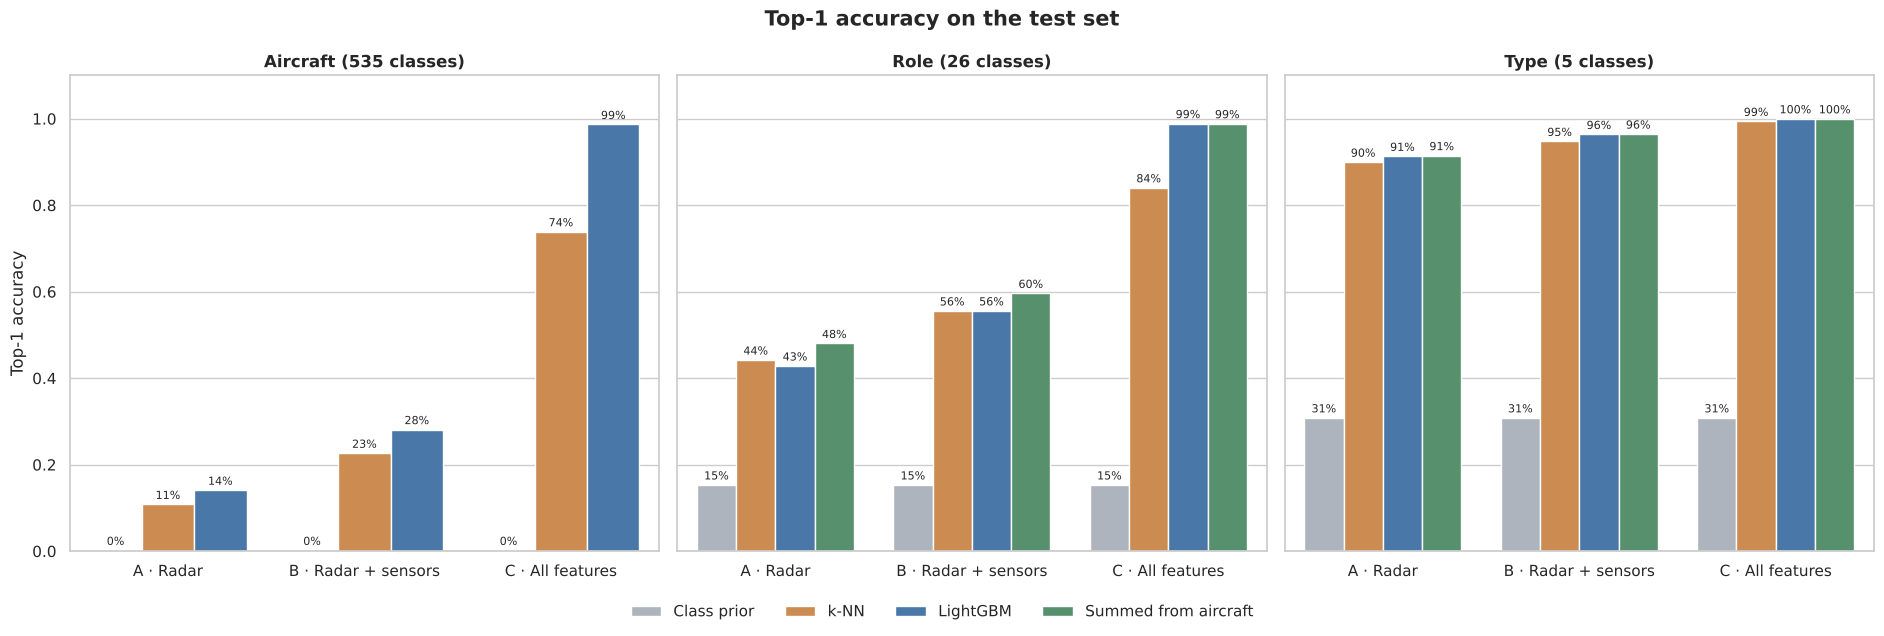

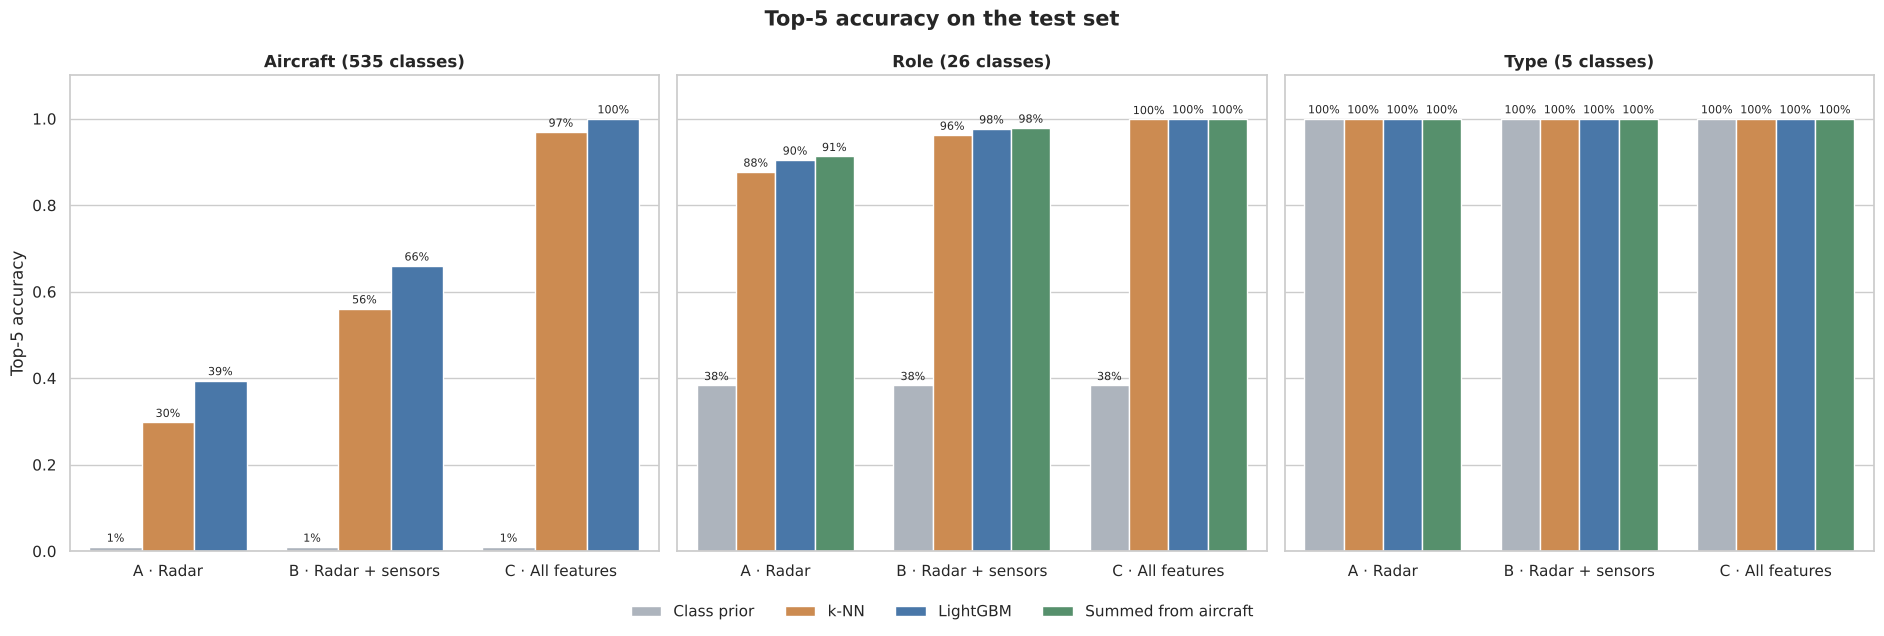

model                   aircraft_summed    knn  lightgbm  prior
target scenario                                                
name   A_radar                      NaN  0.108     0.141  0.002
       B_radar_sensors              NaN  0.227     0.281  0.002
       C_all                        NaN  0.739     0.987  0.002
role   A_radar                    0.480  0.442     0.428  0.153
       B_radar_sensors            0.596  0.556     0.556  0.153
       C_all                      0.989  0.840     0.989  0.153
type   A_radar                    0.915  0.900     0.913  0.308
       B_radar_sensors            0.965  0.948     0.964  0.308
       C_all                      1.000  0.994     1.000  0.308

In [ ]:
model_order = ["prior", "knn", "lightgbm", "aircraft_summed"]
model_labels = {"prior": "Class prior", "knn": "k-NN", "lightgbm": "LightGBM", "aircraft_summed": "Summed from aircraft"}
model_colors = {"Class prior": GREY, "k-NN": ORANGE, "LightGBM": BLUE, "Summed from aircraft": GREEN}

performance = test_results[test_results["model"].isin(model_order)].copy()
performance["model_label"] = performance["model"].map(model_labels)

performance[["target", "scenario", "model", "top1", "top5", "log_loss", "macro_f1"]].sort_values(["target", "scenario", "model"]).to_csv(METRICS_DIR / "performance_comparison.csv", index=False)

for metric, metric_name in {"top1": "Top-1 accuracy", "top5": "Top-5 accuracy"}.items():
    fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)

    for ax, target in zip(axes, TARGET_ORDER):
        data = performance[performance["target"] == target]
        hue_order = [model_labels[m] for m in model_order if m in set(data["model"])]

        sns.barplot(
            data=data,
            x="scenario_label",
            y=metric,
            hue="model_label",
            order=[SCENARIO_LABELS[s] for s in SCENARIO_ORDER],
            hue_order=hue_order,
            palette=model_colors,
            errorbar=None,
            ax=ax
        )

        label_bars(ax)
        ax.set_title(TARGET_LABELS[target], fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel(metric_name)
        ax.set_ylim(0, 1.1)

    fig.suptitle(f"{metric_name} on the test set", fontsize=15, fontweight="bold")
    shared_legend(fig, axes)
    plt.tight_layout()
    save_figure(fig, f"performance_{metric}.png")

display(performance.pivot_table(index=["target", "scenario"], columns="model", values="top1").round(3))


## Ⅱ. Model Calibration

### 8.2 · Reliability Diagrams

Temperature scaling never changes which class ranks first, so top-1, top-5 and macro-F1 are identical
before and after calibration. What it changes is whether the probabilities can be trusted.

A reliability diagram groups predictions by their confidence and compares it with how often they were right.
A perfectly calibrated model lies on the diagonal. ECE is the average gap.


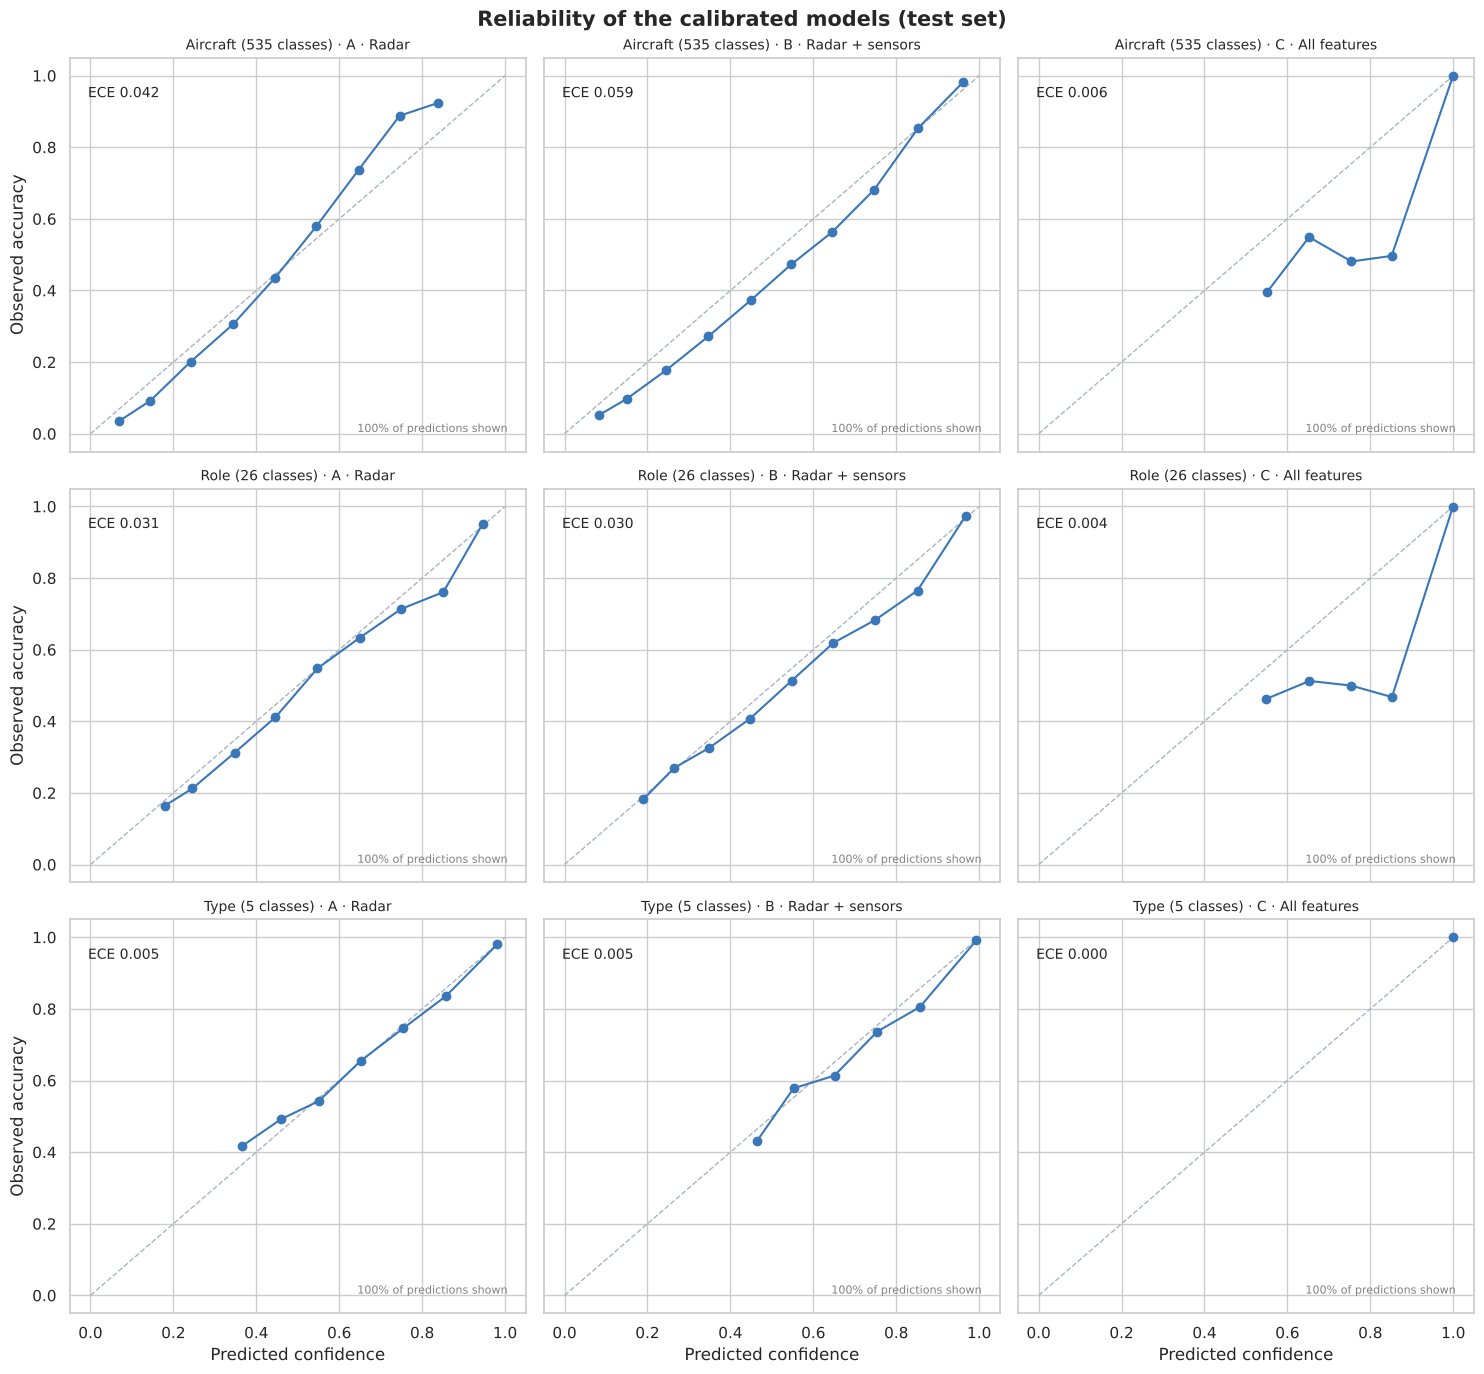

,target,scenario,temperature,log_loss_raw,log_loss_calibrated,brier_raw,brier_calibrated,ece_calibrated
0,name,A_radar,0.9408,3.4845,3.4786,0.9166,0.9172,0.0424
1,name,B_radar_sensors,0.9159,2.2771,2.2668,0.7918,0.7948,0.0591
2,name,C_all,0.8768,0.0277,0.0260,0.0165,0.0171,0.0061
3,role,A_radar,1.0500,1.4261,1.4248,0.6638,0.6626,0.0306
4,role,B_radar_sensors,1.1153,1.0137,1.0101,0.5322,0.5293,0.0299
5,role,C_all,0.9115,0.0204,0.0200,0.0134,0.0137,0.0044
6,type,A_radar,1.0327,0.2429,0.2426,0.1317,0.1315,0.0045
7,type,B_radar_sensors,0.9686,0.0907,0.0909,0.0536,0.0536,0.0051
8,type,C_all,0.1184,0.0000,-0.0000,0.0000,0.0000,0.0000


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 14), sharex=True, sharey=True)

for row, target in enumerate(TARGET_ORDER):
    for col, scenario in enumerate(SCENARIO_ORDER):
        ax = axes[row, col]
        artefact = artefacts[(target, scenario)]
        curve = calibrate.reliability_curve(artefact["proba"], artefact["y"], n_bins=10)

        confidence = np.array(curve["confidence"], dtype=float)
        accuracy = np.array(curve["accuracy"], dtype=float)
        counts = np.array(curve["counts"])
        keep = counts >= 30

        ax.plot([0, 1], [0, 1], linestyle="--", color=GREY, linewidth=1)
        ax.plot(confidence[keep], accuracy[keep], marker="o", color=BLUE)
        ax.set_title(f"{TARGET_LABELS[target]} · {SCENARIO_LABELS[scenario]}", fontsize=10)
        ax.text(0.04, 0.9, f"ECE {curve['ece']:.3f}", transform=ax.transAxes, fontsize=10)
        ax.text(0.96, 0.05, f"{counts[keep].sum() / counts.sum():.0%} of predictions shown", transform=ax.transAxes, fontsize=8, ha="right", color="grey")

        if row == 2:
            ax.set_xlabel("Predicted confidence")
        if col == 0:
            ax.set_ylabel("Observed accuracy")

fig.suptitle("Reliability of the calibrated models (test set)", fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure(fig, "reliability.png")

raw = test_results[test_results["model"] == "lightgbm_raw"].set_index(["target", "scenario"])
cal = test_results[test_results["model"] == "lightgbm"].set_index(["target", "scenario"])

calibration = pd.DataFrame({
    "temperature": cal["temperature"],
    "log_loss_raw": raw["log_loss"],
    "log_loss_calibrated": cal["log_loss"],
    "brier_raw": raw["brier"],
    "brier_calibrated": cal["brier"],
    "ece_calibrated": cal["ece"],
}).reset_index()

calibration.to_csv(METRICS_DIR / "calibration_comparison.csv", index=False)
display(calibration.round(4))


## Ⅲ. Distribution Shift

### 8.3 · Performance Under Distribution Shift

The shifted test set draws speed uniformly instead of around cruise speed and doubles the measurement noise.

Compare top-1 accuracy on the normal and the shifted test set for every target and scenario.


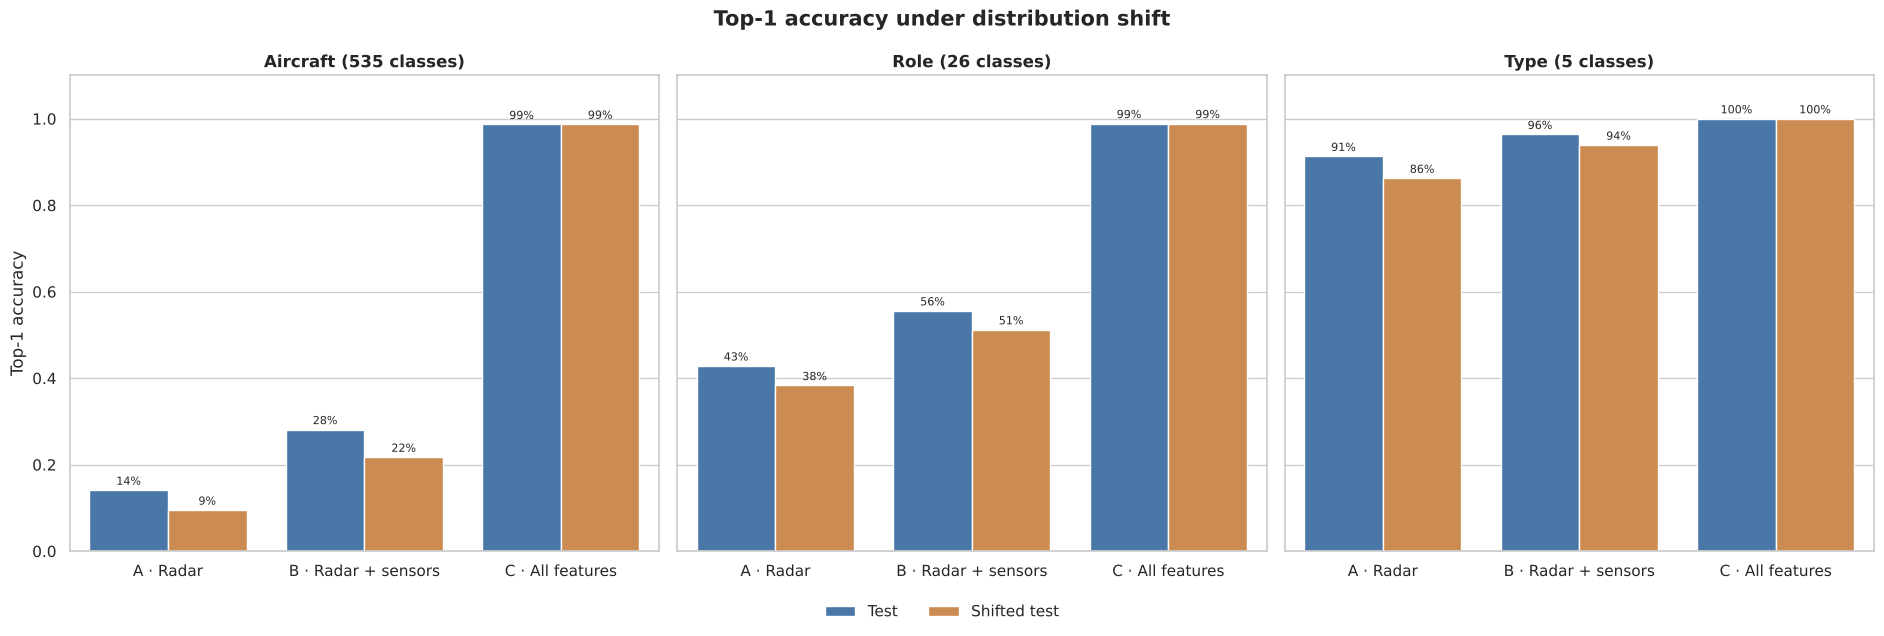

,target,scenario,log_loss_shifted_test,log_loss_test,top1_shifted_test,top1_test,top5_shifted_test,top5_test,top1_change
0,name,A_radar,4.311,3.479,0.095,0.141,0.287,0.395,-0.046
1,name,B_radar_sensors,2.881,2.267,0.217,0.281,0.561,0.660,-0.064
2,name,C_all,0.028,0.026,0.988,0.987,1.000,1.000,0.001
3,role,A_radar,1.706,1.425,0.383,0.428,0.855,0.905,-0.045
4,role,B_radar_sensors,1.218,1.010,0.512,0.556,0.958,0.977,-0.044
5,role,C_all,0.021,0.020,0.989,0.989,1.000,1.000,0.000
6,type,A_radar,0.383,0.243,0.862,0.913,1.000,1.000,-0.051
7,type,B_radar_sensors,0.166,0.091,0.939,0.964,1.000,1.000,-0.025
8,type,C_all,0.000,0.000,1.000,1.000,1.000,1.000,0.000


In [38]:
shift = results[(results["model"] == "lightgbm") & (results["data"] == "full")].copy()
shift["scenario_label"] = shift["scenario"].map(SCENARIO_LABELS)
shift["split_label"] = shift["split"].map({"test": "Test", "shifted_test": "Shifted test"})

comparison = shift.pivot_table(index=["target", "scenario"], columns="split", values=["top1", "top5", "log_loss"])
comparison.columns = [f"{metric}_{split}" for metric, split in comparison.columns]
comparison["top1_change"] = comparison["top1_shifted_test"] - comparison["top1_test"]
comparison = comparison.reset_index()
comparison.to_csv(METRICS_DIR / "distribution_shift_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)

for ax, target in zip(axes, TARGET_ORDER):
    sns.barplot(
        data=shift[shift["target"] == target],
        x="scenario_label",
        y="top1",
        hue="split_label",
        order=[SCENARIO_LABELS[s] for s in SCENARIO_ORDER],
        hue_order=["Test", "Shifted test"],
        palette={"Test": BLUE, "Shifted test": ORANGE},
        errorbar=None,
        ax=ax
    )

    label_bars(ax)
    ax.set_title(TARGET_LABELS[target], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Top-1 accuracy")
    ax.set_ylim(0, 1.1)

fig.suptitle("Top-1 accuracy under distribution shift", fontsize=15, fontweight="bold")
shared_legend(fig, axes)
plt.tight_layout()
save_figure(fig, "distribution_shift.png")

display(comparison.round(3))


## Ⅳ. Tracks

### 8.4 · Accuracy vs Number of Snapshots

A radar follows a contact over time. Combining several snapshots of the same aircraft
(summing log-probabilities) shows how quickly identification improves with track length.


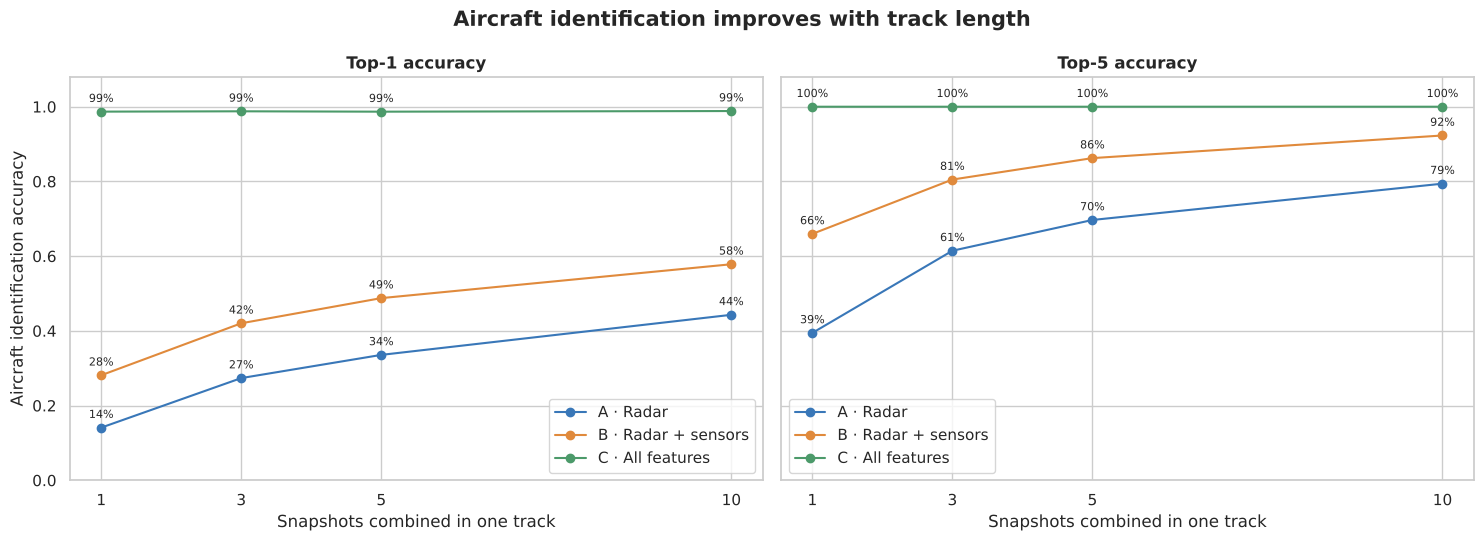

scenario,A_radar,B_radar_sensors,C_all
snapshots,,,
1,0.141,0.281,0.987
3,0.274,0.420,0.988
5,0.336,0.488,0.987
10,0.443,0.578,0.988


In [39]:
track_rows = []

for _, row in test_results[test_results["target"] == "name"].iterrows():
    if row["model"] == "lightgbm":
        length = 1
    elif str(row["model"]).startswith("lightgbm_track"):
        length = int(str(row["model"]).replace("lightgbm_track", ""))
    else:
        continue

    track_rows.append({"scenario": row["scenario"], "snapshots": length, "top1": row["top1"], "top5": row["top5"]})

tracks = pd.DataFrame(track_rows).sort_values(["scenario", "snapshots"])
tracks.to_csv(METRICS_DIR / "track_length.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
colors = dict(zip(SCENARIO_ORDER, [BLUE, ORANGE, GREEN]))

for ax, (metric, metric_name) in zip(axes, {"top1": "Top-1 accuracy", "top5": "Top-5 accuracy"}.items()):
    for scenario in SCENARIO_ORDER:
        data = tracks[tracks["scenario"] == scenario]
        ax.plot(data["snapshots"], data[metric], marker="o", color=colors[scenario], label=SCENARIO_LABELS[scenario])

        for x, y in zip(data["snapshots"], data[metric]):
            ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)

    ax.set_title(metric_name, fontweight="bold")
    ax.set_xlabel("Snapshots combined in one track")
    ax.set_xticks(sorted(tracks["snapshots"].unique()))
    ax.set_ylim(0, 1.08)
    ax.legend(title="")

axes[0].set_ylabel("Aircraft identification accuracy")
fig.suptitle("Aircraft identification improves with track length", fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure(fig, "track_length.png")

display(tracks.pivot_table(index="snapshots", columns="scenario", values="top1").round(3))


## Ⅴ. Operator Filter

### 8.5 · Filter Off vs On

Aircraft-model accuracy on the test rows of types each example country operates,
before and after masking the other types out (section 5).


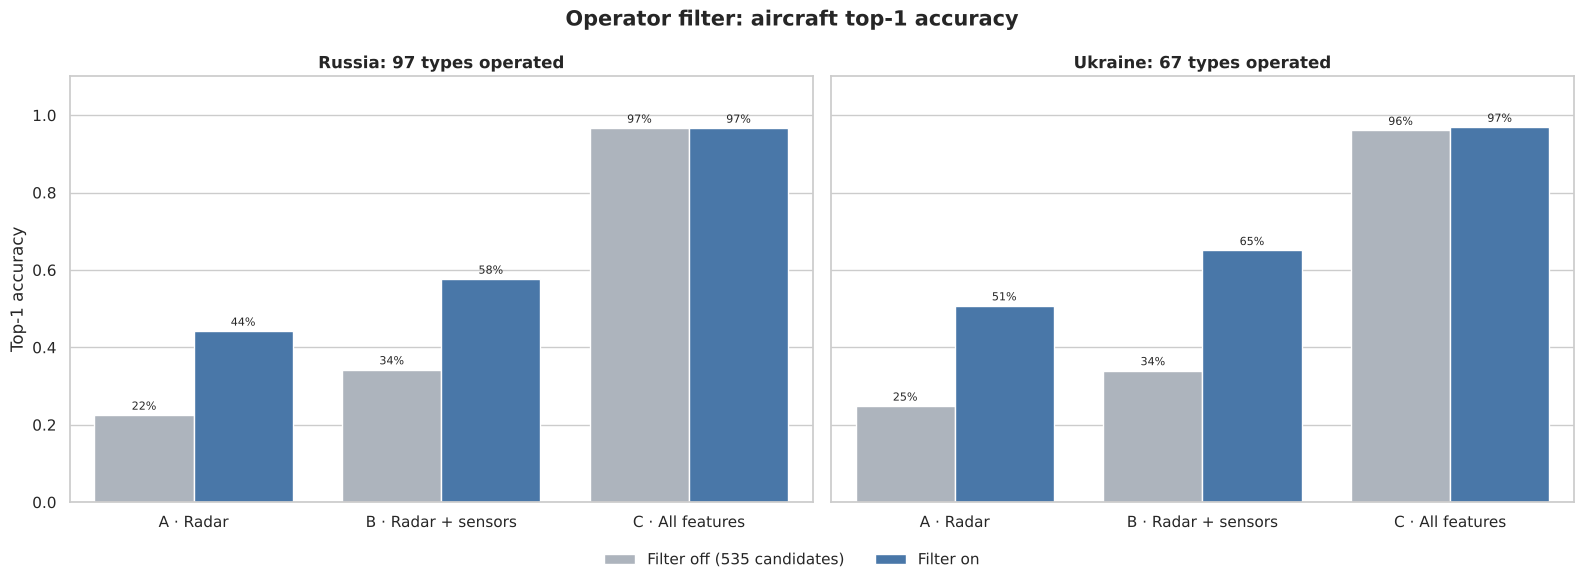

In [40]:
filter_plot = country_results.copy()
filter_plot["scenario_label"] = filter_plot["scenario"].map(SCENARIO_LABELS)
filter_plot["filter_label"] = filter_plot["filter"].map({"off": "Filter off (535 candidates)", "on": "Filter on"})

fig, axes = plt.subplots(1, len(cfg["filter_examples"]), figsize=(8 * len(cfg["filter_examples"]), 5.5), sharey=True, squeeze=False)

for ax, country in zip(axes[0], cfg["filter_examples"]):
    data = filter_plot[filter_plot["selection"] == country]
    n_on = int(data.loc[data["filter"] == "on", "n_classes"].iloc[0])

    sns.barplot(
        data=data,
        x="scenario_label",
        y="top1",
        hue="filter_label",
        order=[SCENARIO_LABELS[s] for s in SCENARIO_ORDER],
        hue_order=["Filter off (535 candidates)", "Filter on"],
        palette={"Filter off (535 candidates)": GREY, "Filter on": BLUE},
        errorbar=None,
        ax=ax
    )

    label_bars(ax)
    ax.set_title(f"{country}: {n_on} types operated", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Top-1 accuracy")
    ax.set_ylim(0, 1.1)

fig.suptitle("Operator filter: aircraft top-1 accuracy", fontsize=15, fontweight="bold")
shared_legend(fig, axes)
plt.tight_layout()
save_figure(fig, "operator_filter.png")


## Ⅵ. Experiments

### 8.6 · Ablation: Without Rule-Estimated Values

About a third of the filled feature values are rule-based estimates.
Compare the models trained with them (full) and with every estimated cell blanked (ablation).


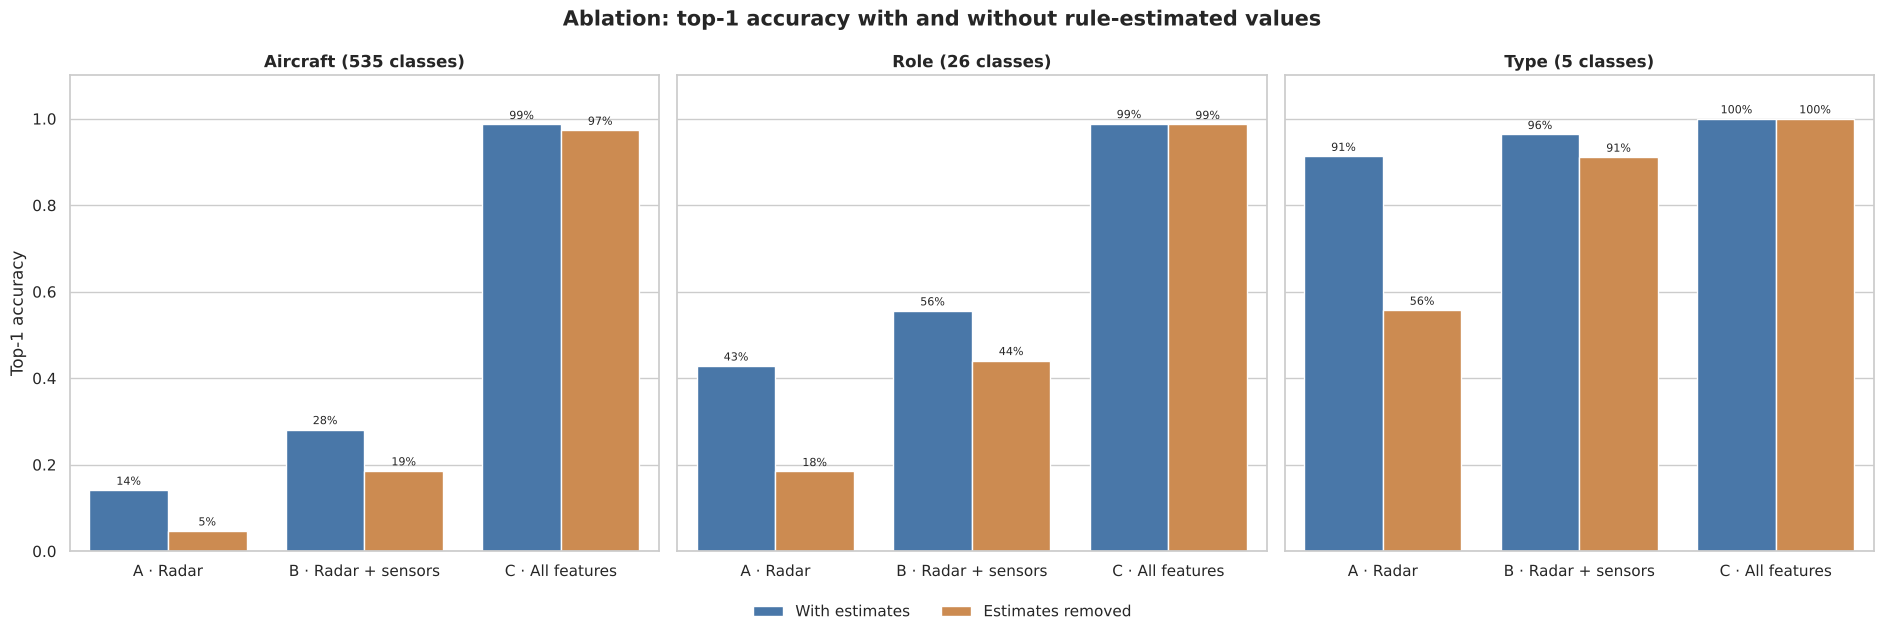

data_label              Estimates removed  With estimates  change
target scenario                                                  
name   A_radar                      0.047           0.141  -0.094
       B_radar_sensors              0.186           0.281  -0.095
       C_all                        0.973           0.987  -0.013
role   A_radar                      0.184           0.428  -0.244
       B_radar_sensors              0.441           0.556  -0.115
       C_all                        0.987           0.989  -0.002
type   A_radar                      0.557           0.913  -0.356
       B_radar_sensors              0.911           0.964  -0.052
       C_all                        1.000           1.000   0.000

In [41]:
ablation = pd.concat([
    test_results[test_results["model"] == "lightgbm"].assign(data_label="With estimates"),
    ablation_results[(ablation_results["split"] == "test") & (ablation_results["model"] == "lightgbm")].assign(data_label="Estimates removed"),
], ignore_index=True)
ablation["scenario_label"] = ablation["scenario"].map(SCENARIO_LABELS)

ablation_table = ablation.pivot_table(index=["target", "scenario"], columns="data_label", values="top1")
ablation_table["change"] = ablation_table["Estimates removed"] - ablation_table["With estimates"]
ablation_table.reset_index().to_csv(METRICS_DIR / "ablation_comparison.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True)

for ax, target in zip(axes, TARGET_ORDER):
    sns.barplot(
        data=ablation[ablation["target"] == target],
        x="scenario_label",
        y="top1",
        hue="data_label",
        order=[SCENARIO_LABELS[s] for s in SCENARIO_ORDER],
        hue_order=["With estimates", "Estimates removed"],
        palette={"With estimates": BLUE, "Estimates removed": ORANGE},
        errorbar=None,
        ax=ax
    )

    label_bars(ax)
    ax.set_title(TARGET_LABELS[target], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Top-1 accuracy")
    ax.set_ylim(0, 1.1)

fig.suptitle("Ablation: top-1 accuracy with and without rule-estimated values", fontsize=15, fontweight="bold")
shared_legend(fig, axes)
plt.tight_layout()
save_figure(fig, "ablation.png")

display(ablation_table.round(3))


### 8.7 · Unseen Aircraft Families

Role and type models evaluated on whole families that were held out of training (5 folds),
next to the normal test set where every aircraft was seen during training.


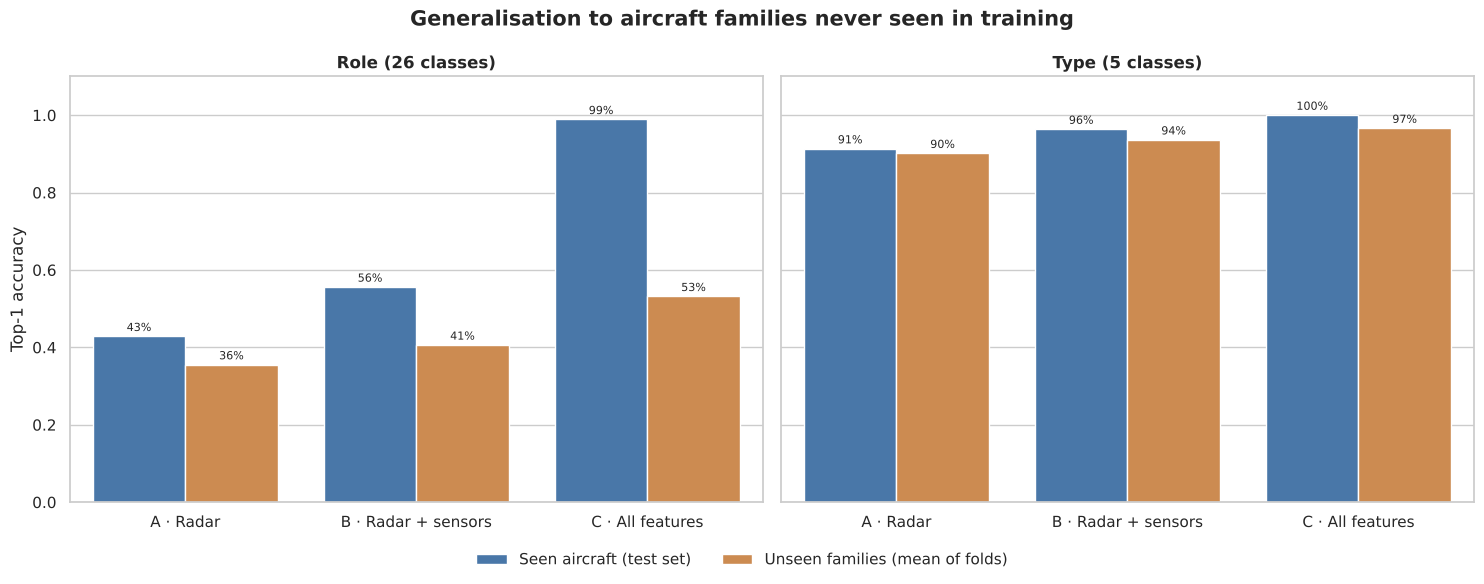

,target,scenario,mean,std,seen_top1
0,role,A_radar,0.355,0.015,0.428
1,role,B_radar_sensors,0.406,0.028,0.556
2,role,C_all,0.532,0.028,0.989
3,type,A_radar,0.901,0.016,0.913
4,type,B_radar_sensors,0.936,0.013,0.964
5,type,C_all,0.966,0.016,1.000


In [42]:
unseen = family_results.groupby(["target", "scenario"])["top1"].agg(["mean", "std"]).reset_index()
seen = test_results[(test_results["model"] == "lightgbm") & (test_results["target"].isin(["role", "type"]))][["target", "scenario", "top1"]]
unseen = unseen.merge(seen.rename(columns={"top1": "seen_top1"}), on=["target", "scenario"])
unseen.to_csv(METRICS_DIR / "unseen_families_summary.csv", index=False)

plot = pd.concat([
    unseen.assign(value=unseen["seen_top1"], kind="Seen aircraft (test set)"),
    unseen.assign(value=unseen["mean"], kind="Unseen families (mean of folds)"),
], ignore_index=True)
plot["scenario_label"] = plot["scenario"].map(SCENARIO_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

for ax, target in zip(axes, ["role", "type"]):
    sns.barplot(
        data=plot[plot["target"] == target],
        x="scenario_label",
        y="value",
        hue="kind",
        order=[SCENARIO_LABELS[s] for s in SCENARIO_ORDER],
        hue_order=["Seen aircraft (test set)", "Unseen families (mean of folds)"],
        palette={"Seen aircraft (test set)": BLUE, "Unseen families (mean of folds)": ORANGE},
        errorbar=None,
        ax=ax
    )

    label_bars(ax)
    ax.set_title(TARGET_LABELS[target], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Top-1 accuracy")
    ax.set_ylim(0, 1.1)

fig.suptitle("Generalisation to aircraft families never seen in training", fontsize=15, fontweight="bold")
shared_legend(fig, axes)
plt.tight_layout()
save_figure(fig, "unseen_families.png")

display(unseen.round(3))


## Ⅶ. Confusions

### 8.8 · Role and Type Confusion Matrices

Row-normalised confusion matrices for scenario B (radar + sensors): each row shows where the
snapshots of one true class end up. Aircraft-level matrices stay out of the public notebook.


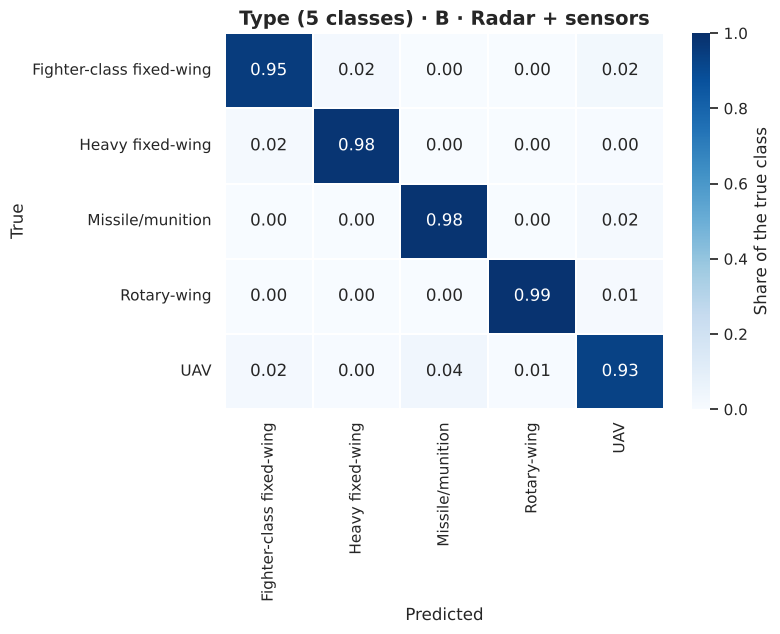

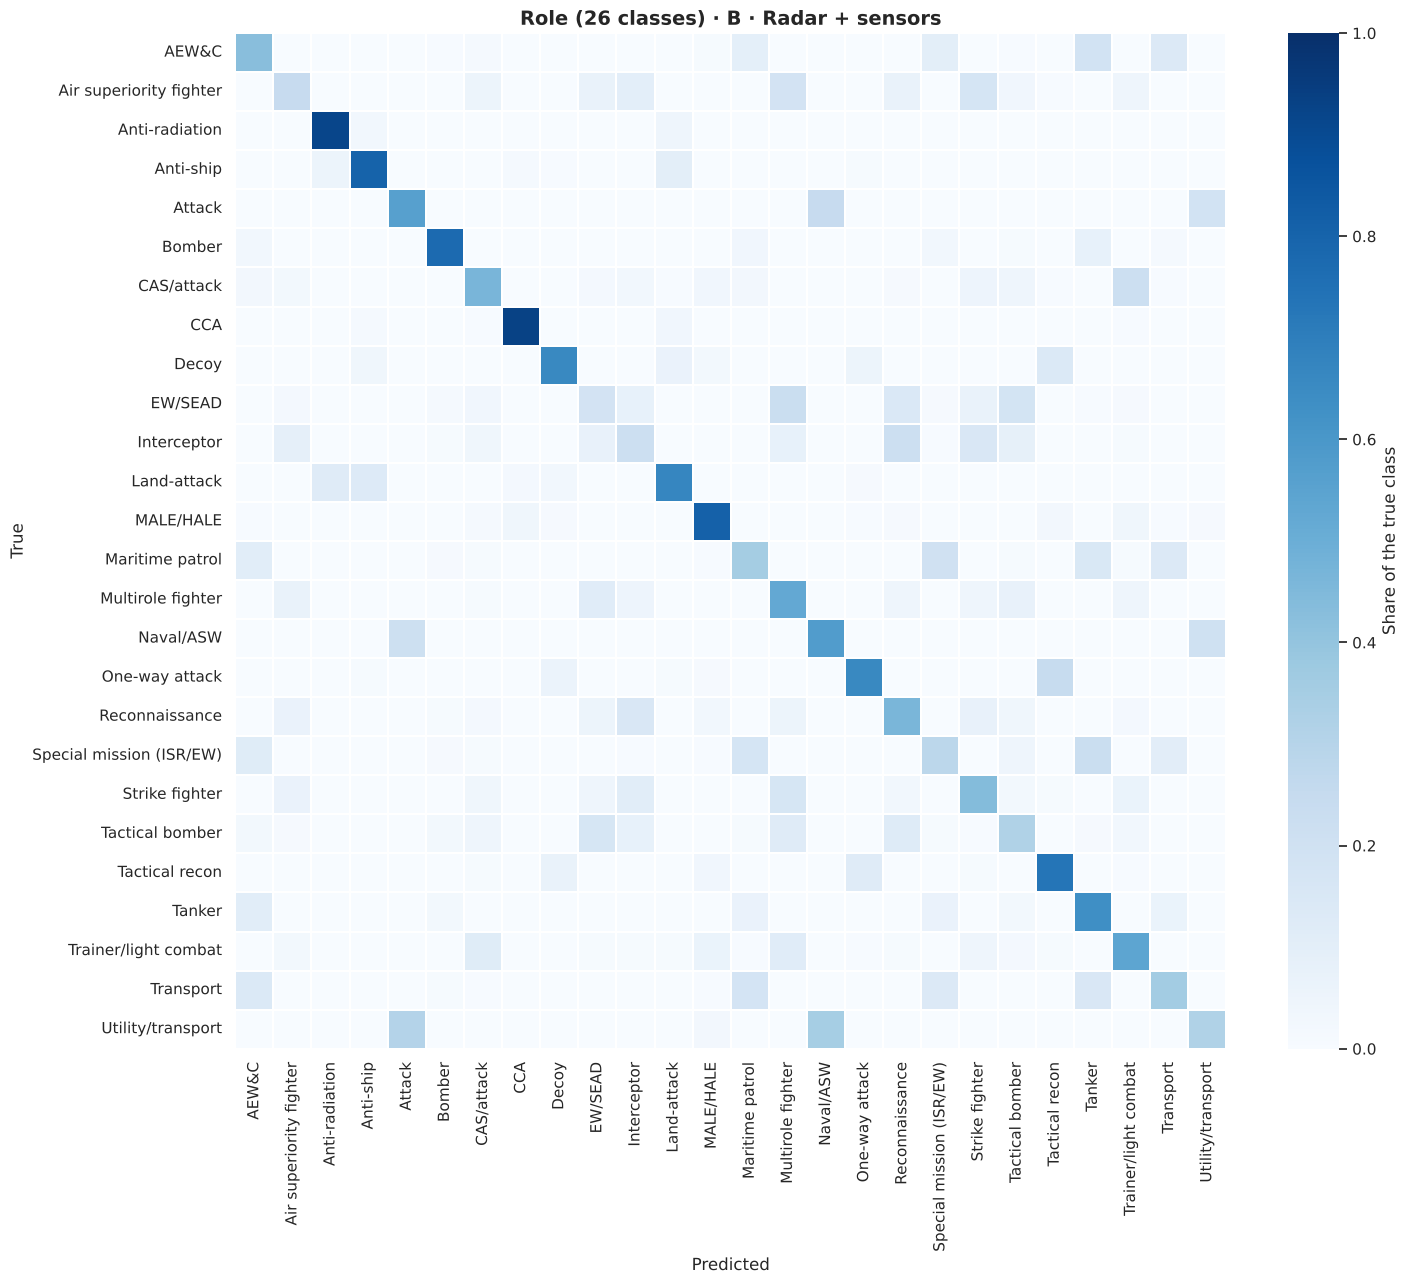

In [43]:
for target, size in (("type", (8, 6.5)), ("role", (15, 13))):
    artefact = artefacts[(target, "B_radar_sensors")]
    classes = np.asarray(artefact["classes"])
    y_true = artefact["y"]
    y_pred = artefact["proba"].argmax(axis=1)

    matrix = np.zeros((len(classes), len(classes)))
    np.add.at(matrix, (y_true, y_pred), 1)
    matrix = matrix / matrix.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=size)

    sns.heatmap(
        pd.DataFrame(matrix, index=classes, columns=classes),
        cmap="Blues",
        vmin=0,
        vmax=1,
        annot=target == "type",
        fmt=".2f",
        linewidths=0.3,
        linecolor="white",
        cbar_kws={"label": "Share of the true class"},
        ax=ax
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{TARGET_LABELS[target]} · B · Radar + sensors", fontsize=14, fontweight="bold")
    plt.tight_layout()
    save_figure(fig, f"confusion_{target}_B.png")


## Ⅷ. Feature Importance

### 8.9 · Feature Contribution Analysis

Share of the total split gain per input feature, for every target and scenario.
Shares make the scenarios comparable even though their models have different sizes.


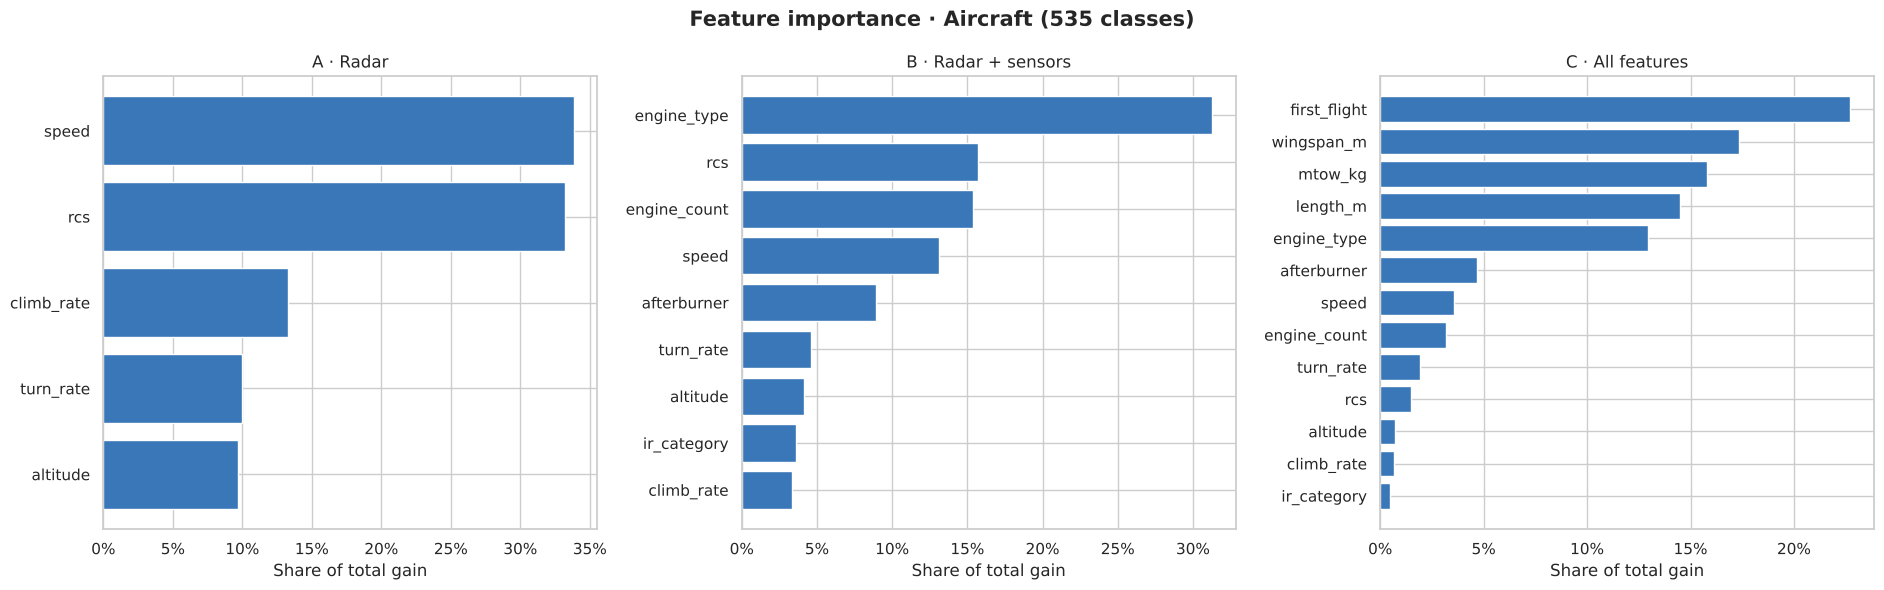

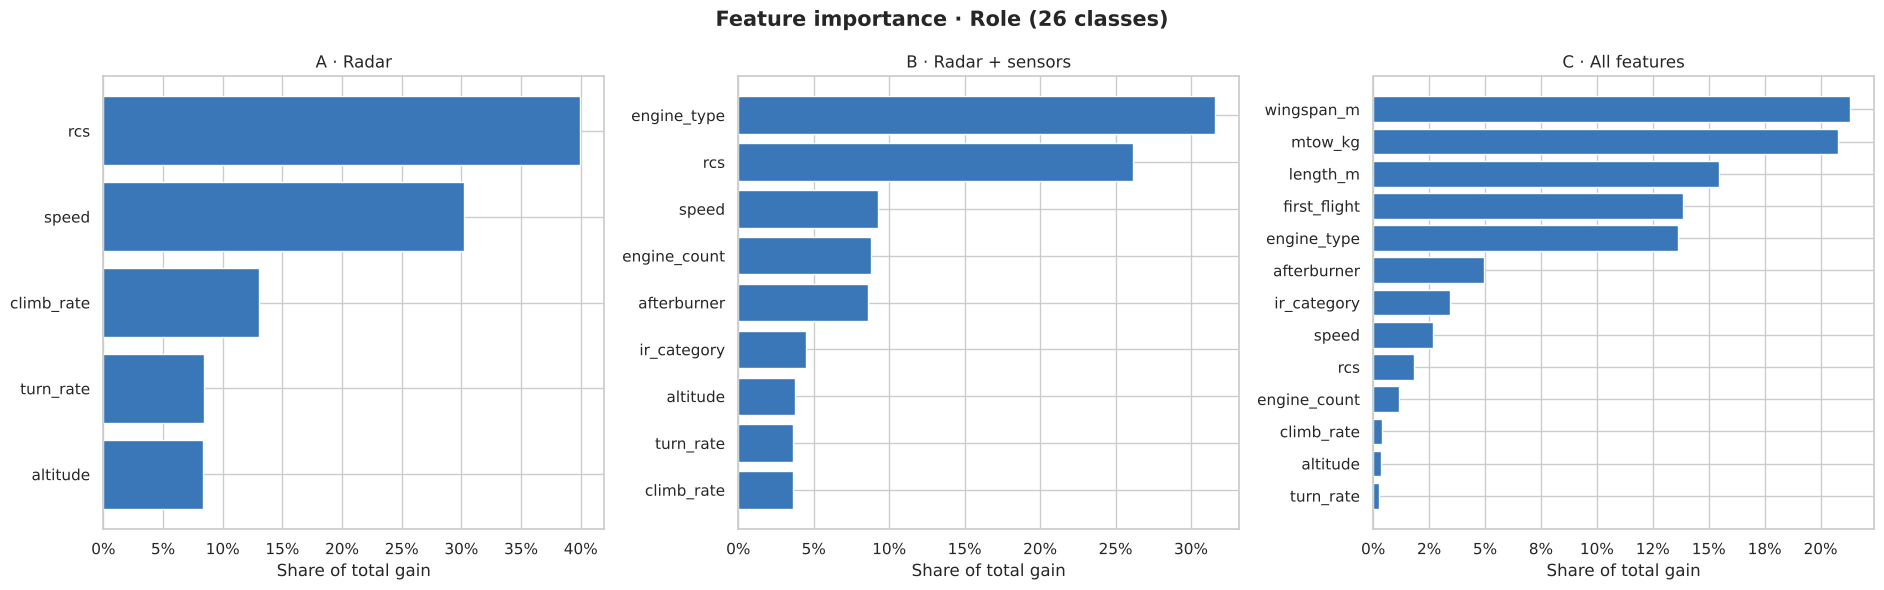

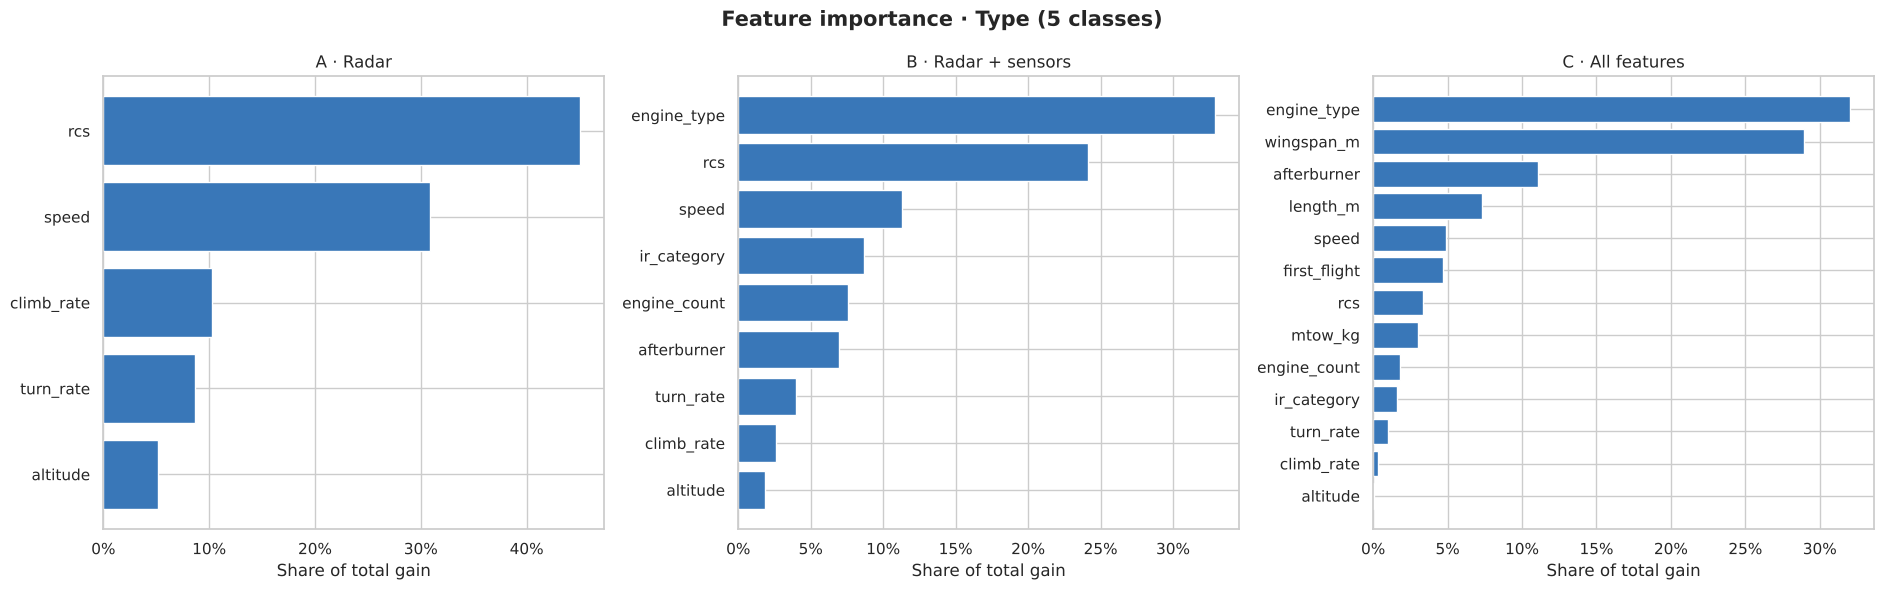

In [44]:
model_dir = Path("models")
aliases = {"name": "aircraft", "role": "role", "type": "type"}
importance_rows = []

for target, alias in aliases.items():
    for scenario in SCENARIO_ORDER:
        model_path = model_dir / f"{alias}_{scenario}.txt"
        meta_path = model_dir / f"{alias}_{scenario}.json"

        if not model_path.exists() or not meta_path.exists():
            print(f"Missing: {model_path.name}")
            continue

        feature_names = json.loads(meta_path.read_text(encoding="utf-8"))["features"]
        booster = lgb.Booster(model_file=str(model_path))

        importance_rows.append(pd.DataFrame({
            "target": target,
            "scenario": scenario,
            "feature": feature_names,
            "gain": booster.feature_importance("gain"),
            "split": booster.feature_importance("split"),
        }))

        del booster
        gc.collect()

importance_df = pd.concat(importance_rows, ignore_index=True)
importance_df["gain_share"] = importance_df["gain"] / importance_df.groupby(["target", "scenario"])["gain"].transform("sum")
importance_df.to_csv(METRICS_DIR / "feature_importance.csv", index=False)

for target in TARGET_ORDER:
    fig, axes = plt.subplots(1, 3, figsize=(19, 6))

    for ax, scenario in zip(axes, SCENARIO_ORDER):
        data = importance_df[(importance_df["target"] == target) & (importance_df["scenario"] == scenario)]
        top = data.nlargest(15, "gain_share").sort_values("gain_share")

        ax.barh(top["feature"], top["gain_share"], color=BLUE)
        ax.set_title(SCENARIO_LABELS[scenario])
        ax.set_xlabel("Share of total gain")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

    fig.suptitle(f"Feature importance · {TARGET_LABELS[target]}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    save_figure(fig, f"feature_importance_{target}.png")


## Ⅸ. Feature Space

### 8.10 · What the Radar Sees

Density of simulated radar snapshots (training set) for each class: speed against altitude
and speed against radar cross-section. Overlapping areas are where a single snapshot cannot
tell the classes apart, which explains the radar-only results.

Contours of sampled observations are shown instead of the specification rows, so no aircraft's values are published.


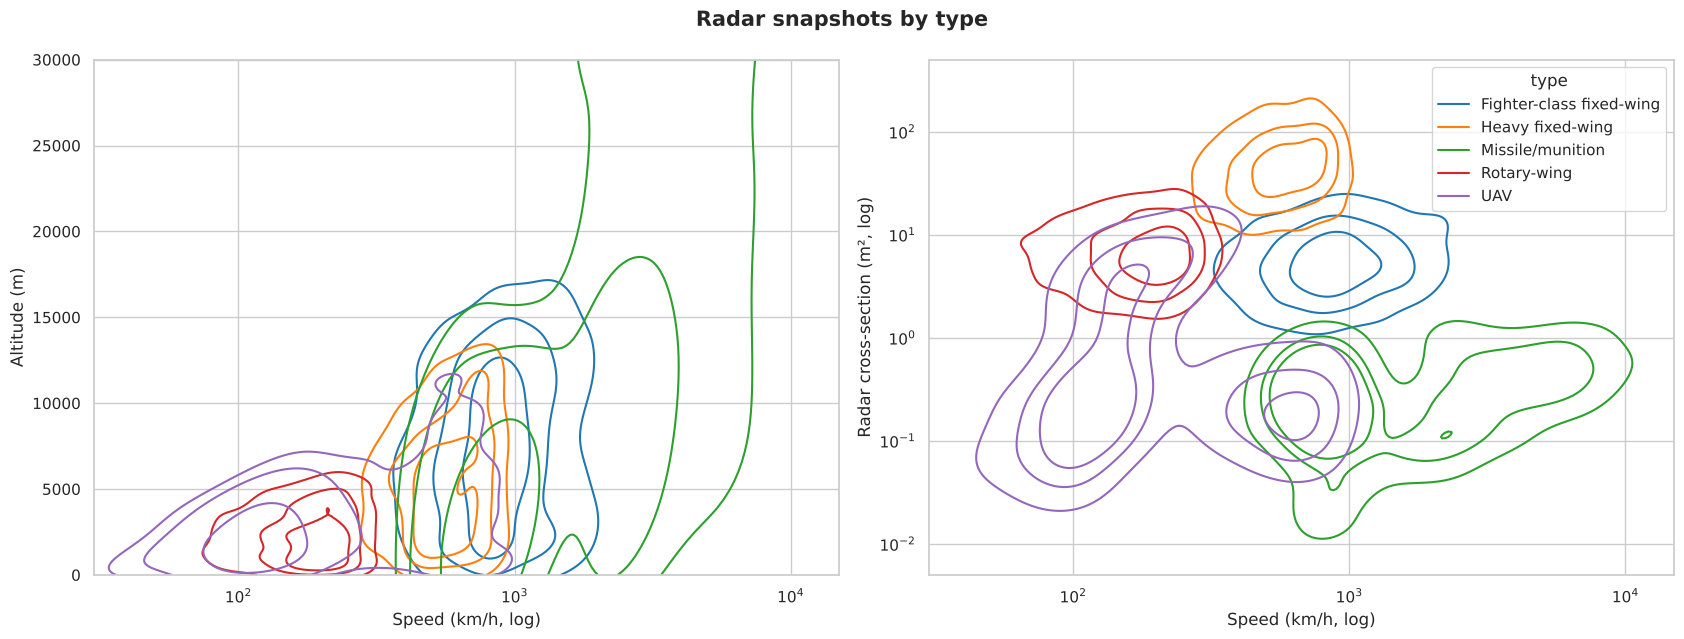

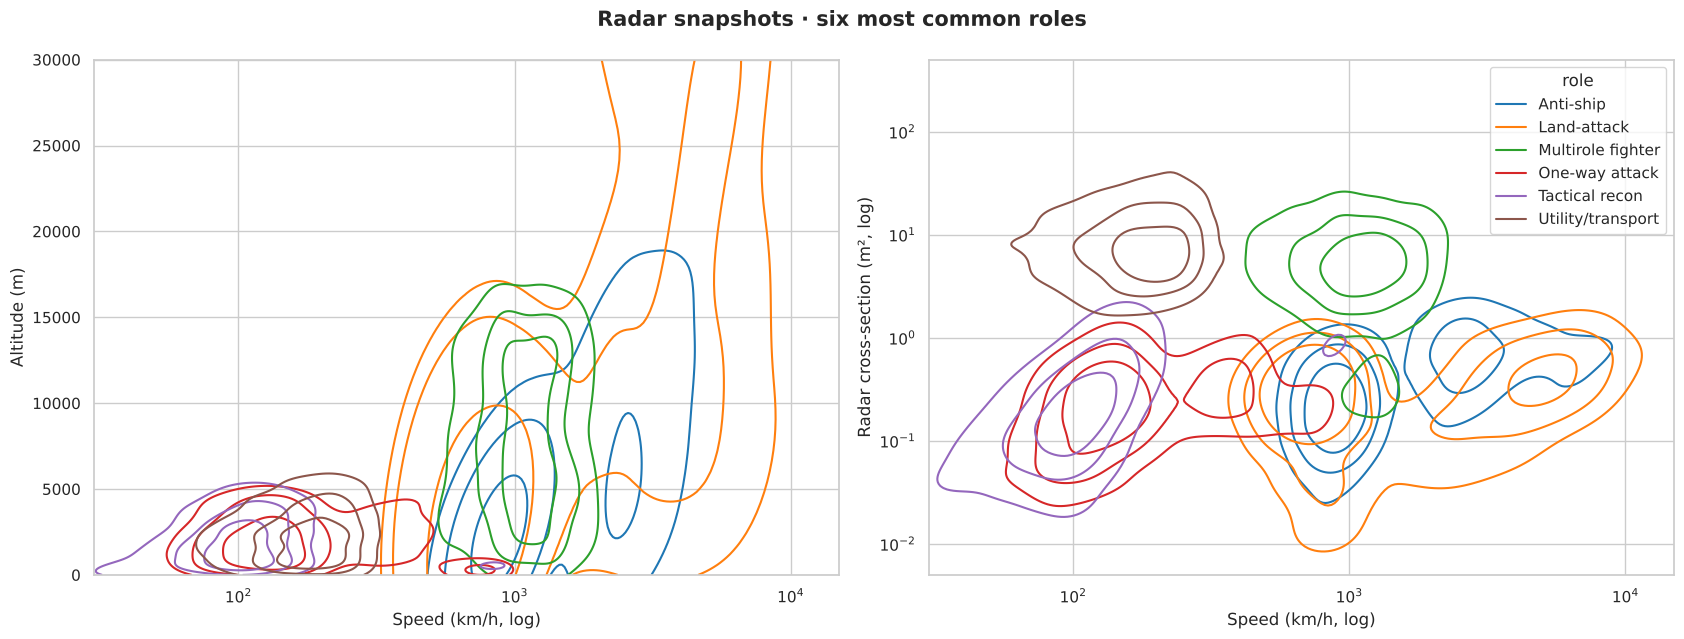

In [45]:
# shuffle, then at most 2500 snapshots per class
snapshots = splits["train"].sample(frac=1, random_state=0).groupby("type").head(2500)
snapshots = snapshots[(snapshots["speed"] > 0) & (snapshots["rcs"] > 0)]

for target in ["type", "role"]:
    data = snapshots.copy()

    if target == "role":
        top_roles = df["role"].value_counts().head(6).index
        data = splits["train"][splits["train"]["role"].isin(top_roles)]
        data = data.sample(frac=1, random_state=0).groupby("role").head(2500)
        data = data[(data["speed"] > 0) & (data["rcs"] > 0)]

    categories = sorted(data[target].unique())
    palette = dict(zip(categories, sns.color_palette("tab10", len(categories))))

    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

    for ax, (y, y_label) in zip(axes, (("altitude", "Altitude (m)"), ("rcs", "Radar cross-section (m², log)"))):
        sns.kdeplot(
            data=data,
            x="speed",
            y=y,
            hue=target,
            hue_order=categories,
            palette=palette,
            levels=4,
            thresh=0.2,
            log_scale=(True, y == "rcs"),
            clip=((None, None), (0, None)) if y == "altitude" else None,
            common_norm=False,
            legend=ax is axes[-1],
            ax=ax
        )

        ax.set_xlim(30, 15000)
        if y == "altitude":
            ax.set_ylim(0, 30000)
        else:
            ax.set_ylim(0.005, 500)
        ax.set_xlabel("Speed (km/h, log)")
        ax.set_ylabel(y_label)

    title = "Radar snapshots by type" if target == "type" else "Radar snapshots · six most common roles"
    fig.suptitle(title, fontsize=15, fontweight="bold")
    plt.tight_layout()
    save_figure(fig, f"feature_space_{target}.png")


## Ⅹ. Class Imbalance

### 8.11 · Class Distribution Analysis

Every aircraft gets the same number of snapshots, so the role and type classes are only as unbalanced
as the number of aircraft in each. The role and type models use balanced class weights to compensate.


ROLE: 26 classes, largest Land-attack (16,400), smallest Decoy (1,200), ratio 13.7:1
TYPE: 5 classes, largest Fighter-class fixed-wing (33,000), smallest Rotary-wing (12,600), ratio 2.6:1


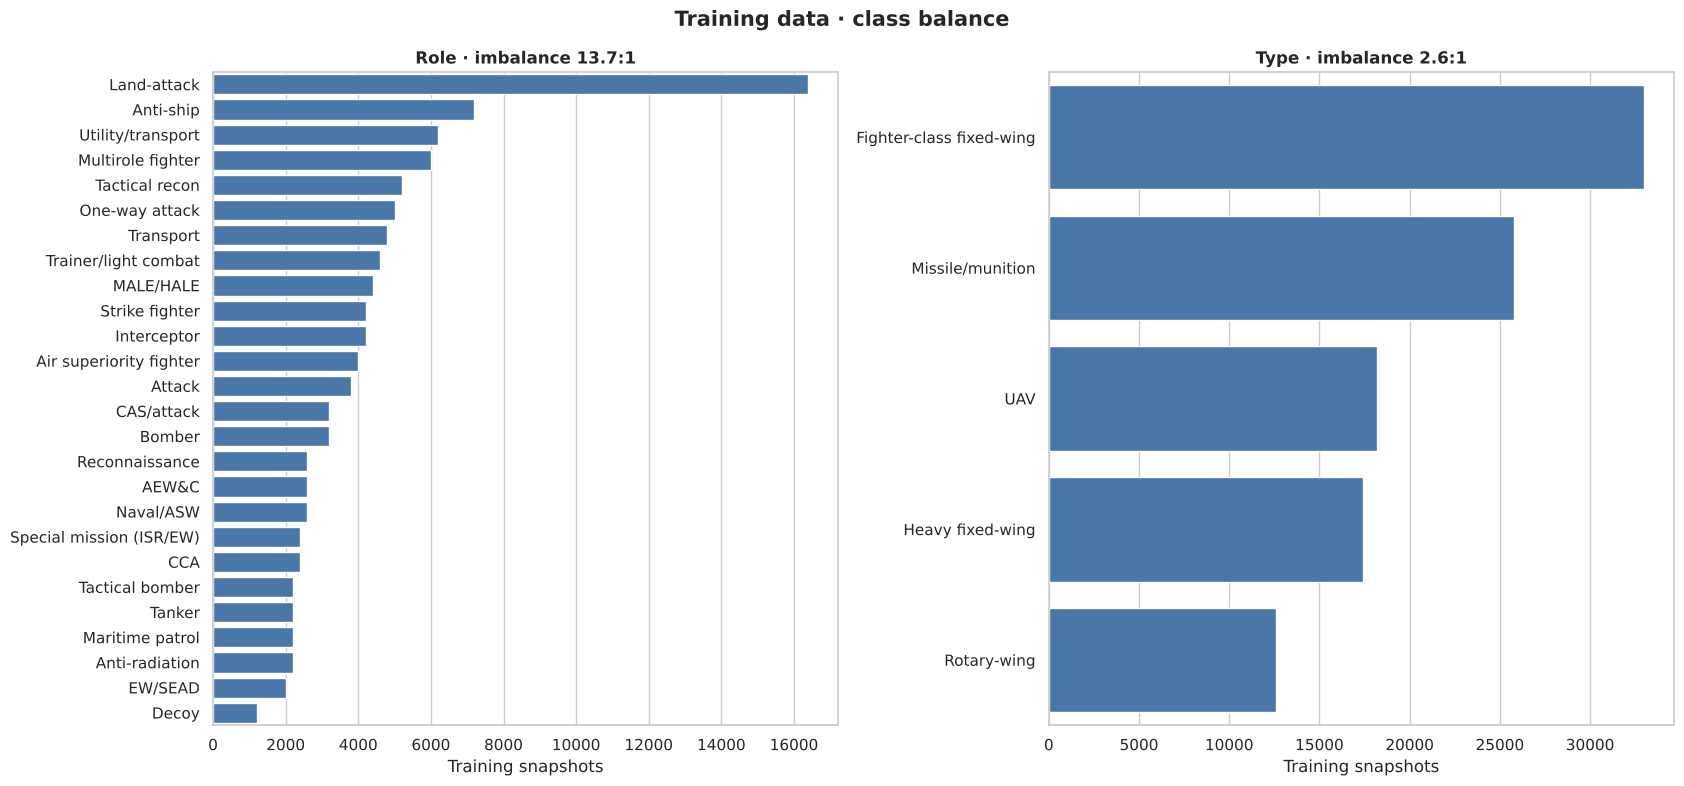

In [46]:
train_obs = splits["train"]
rows = []

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, target in zip(axes, ["role", "type"]):
    counts = train_obs[target].value_counts(dropna=True)

    distribution = pd.DataFrame({
        "target": target,
        "class": counts.index.astype(str),
        "count": counts.values,
        "share": counts.values / counts.sum()
    })

    rows.append(distribution)

    sns.barplot(data=distribution, x="count", y="class", color=BLUE, ax=ax)

    ratio = counts.max() / counts.min()
    ax.set_title(f"{target.title()} · imbalance {ratio:.1f}:1", fontweight="bold")
    ax.set_xlabel("Training snapshots")
    ax.set_ylabel("")

    print(f"{target.upper()}: {len(counts)} classes, largest {counts.index[0]} ({counts.iloc[0]:,}), smallest {counts.index[-1]} ({counts.iloc[-1]:,}), ratio {ratio:.1f}:1")

fig.suptitle("Training data · class balance", fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure(fig, "class_imbalance.png")

pd.concat(rows, ignore_index=True).to_csv(METRICS_DIR / "class_distribution.csv", index=False)


---

<div align="center">

*End of Section 08 · Model Analysis & Visualization*

**Model performance and experimental results have been evaluated.**

</div>

---


## 9. Conclusions

**What works**

- **One radar snapshot is not enough to name an aircraft.** On radar alone the model is right 14% of the time (chance is 0.2%, k-NN 11%) and has the answer in its top 5 about 40% of the time. Engine and IR cues double that to 28% and 66%.
- **Watching longer helps the most.** Combining ten snapshots of the same contact brings radar-only top-1 to 44% and top-5 to 79%. With sensors it is 58% and 92%.
- **Knowing who could be flying helps just as much.** Limiting the answer to the types one country operates roughly doubles top-1: 22% → 44% for Russia, 25% → 51% for Ukraine on radar only. Top-5 reaches 88% and 96%. No retraining is needed.
- **Broad questions are easy, narrow ones are hard.** The coarse type (fighter, heavy, helicopter, UAV, missile) is right 91% of the time on radar alone, the role 43%. Adding up the aircraft model's probabilities gives a better role (48%) than the dedicated role model, so one aircraft model can answer all three questions.
- **The probabilities can be trusted.** Calibration error is at most 0.06: when the model says 60%, it is right about 60% of the time. The models were already close to calibrated, so temperature scaling changed little.

**What to be careful about**

- **The results depend on the estimated values.** Almost every RCS value is a rule-based estimate. With the estimates removed, radar-only accuracy drops by 40–70% (type 91% → 56%, role 43% → 18%, aircraft 14% → 5%). Real-world accuracy depends on how good those estimates are.
- **Noisier data costs some accuracy but does not break the models.** With uniform speeds and double noise, radar-only aircraft top-1 goes from 14% to 9.5% and type from 91% to 86%.
- **The models know aircraft, not general rules.** On families they never saw, the coarse type stays above 90%, but the role drops, most in scenario C (99% → 53%). Size and year features identify known aircraft rather than describe what a new one is for.
- **Scenario C is an upper bound.** With the full spec sheet the task becomes a lookup (first-flight year is its top feature), not field identification.
- **Some aircraft cannot be told apart at all.** Near-identical variants share the same kinematics (5 pairs are exact duplicates in the features).

**Next steps:** recorded tracks instead of simulated ones, RCS that depends on viewing angle, better sourced RCS figures, and combining tracks with the operator filter in the app.
